# Spectroscopic reference set (part 2)

Real S-PLUS galaxies whose labels come from **Bagpipes fits to their SDSS spectra under exactly the training prior** (`synthetic_model.py`), so they test the ML model on real data with labels it can match.

**Model:** Bagpipes' delayed-τ star formation history, SFR(t) ∝ t e^(−t/τ) since star formation began, with one metallicity Z for all stars (no age bins, no enrichment law); Charlot & Fall (2000) dust and nebular emission. The fitted parameters are the age (0.05 Gyr to the age of the Universe at the galaxy's redshift minus 0.1 Gyr), τ (0.01–20 Gyr) and Z (0.005–2.5 Z☉), all log-uniform, then A_V, τ_BC and log U; the spectral fits add the velocity dispersion and a noise scale. Every posterior sample carries the training set's labels (`sm.TRAINING_LABELS`): the parameters, their logs, log M*, the SFR over the last 100 Myr, the mass-weighted age and the formed-mass fractions younger than 0.1 Gyr, between 0.1 and 1 Gyr and older.

Firefly (SDSS DR16) only selects the galaxies; the fits are validated against the spectra themselves (spectral indices), Halpha SFRs, Gallazzi et al. (2005) ages and metallicities, and scaling relations (section 7).

**Inputs:** `dr3_corrected.csv`, `../Data/sdss_eboss_firefly-dr16.fits`, `literature/` (MPA-JHU and Gallazzi tables), `../dustMaps/csfd/`, `training_set.parquet` and `splus_noise_model.csv` (part 1), SDSS spectra (downloaded), S-PLUS Cloud aperture photometry (cached in `splus_aperture_photometry.csv`; `SPLUS_USERNAME` / `SPLUS_PASSWORD` are needed only for galaxies missing from the cache).
**Outputs:** `spectra/`, `spectral_fits/jobs/` (one `.npz` per fit job), `spectral_fits/` (one `.h5` per finished fit, plus `fit_log.csv` and, for Slurm tasks, `fit_logs/<job_id>.csv`), `spectral_fits/selection.csv` (selected galaxies, append-only), `spectral_fits/failures.csv` (download and prepare failures), `spectral_fits/calibration_mocks.joblib`, `spectral_fits/superseded/` and `photometric_fits/superseded/` (fits, mocks, mock jobs and run logs of an earlier model or run), `photometric_fits/jobs/` and `photometric_fits/calibration_mocks.joblib` (photometric fits, section 6b), `photometric_fits_dblplaw/jobs/` and `photometric_fits_dblplaw/calibration_mocks.joblib` (double-power-law photometric fits, section 6c), `cross_fit_mocks.joblib` in both photometric folders and `photometric_cross_fits.csv` (cross-fits, section 6c), `spectroscopic_reference.csv`, `validation_summary.csv`, `validation_indices.png`, `validation_halpha_gallazzi.png`, `validation_relations.png`.
**Run:** top to bottom with the *Inference4ETGs (MultiNest)* kernel, after `training_set.ipynb`. The notebook does not run the fits: it exports one job per galaxy and per calibration mock to `spectral_fits/jobs/`, and `run_spectral_fits.py` fits them outside the notebook (one core per fit, on a many-core PC or a Slurm cluster; set `RUN_FITS_HERE = True` to start it from the notebook). Copy the resulting `.h5` files back into `spectral_fits/` and re-run the analysis cells: they accept zero, some or all fits. The fitter must pass a **calibration test** on mocks drawn from the prior; the verdict is stored as `fitter_calibrated` in the reference CSV.

Spectra fit 3″ (SDSS) or 2″ (BOSS) fibres, so photometry is the 3″ S-PLUS aperture, and BOSS galaxies are reported separately. The **test** half of the split is used once, for the final ML evaluation; the grid's 168 galaxies come first, then (`FIT_EVERY_GALAXY`) every other S-PLUS galaxy with an SDSS/BOSS spectrum.

In [ ]:
import glob
import os
import subprocess
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord, match_coordinates_sky
from astropy.io import fits
from astroquery.sdss import SDSS
from dustmaps.csfd import CSFDQuery
import joblib

import synthetic_model as sm

# Files and folders
SPLUS_FILE = "dr3_corrected.csv"
FIREFLY_FULL_FILE = "../Data/sdss_eboss_firefly-dr16.fits"
FIREFLY_SLIM_FILE = "../Data/sdss_eboss_firefly-dr16_slim.fits"   # make_slim_firefly.py: same result, small upload
FIREFLY_FILE = FIREFLY_SLIM_FILE if os.path.exists(FIREFLY_SLIM_FILE) else FIREFLY_FULL_FILE
DUST_MAP_FILE = "../dustMaps/csfd/csfd_ebv.fits"
DUST_MASK_FILE = "../dustMaps/csfd/mask.fits"
TRAINING_FILE = "training_set.parquet"
SPECTRA_DIRECTORY = "spectra"
FITS_DIRECTORY = "spectral_fits"
JOBS_DIRECTORY = "spectral_fits/jobs"                   # exported fit jobs, one .npz each
FAILURES_FILE = "spectral_fits/failures.csv"
SKIPPED_JOBS_FILE = "skipped_fit_jobs.txt"   # fit jobs deliberately left unfitted (slow mocks)
SELECTION_FILE = "spectral_fits/selection.csv"   # selected specobjids, append-only across passes
# Calibration mocks and true labels, kept so their fits stay checkable
MOCK_FILE = os.path.join(FITS_DIRECTORY, sm.CALIBRATION_MOCK_FILE)
OLD_MOCK_FILE = "spectral_fits/mocks.joblib"           # the first run's inject-and-recover mocks (superseded)
PHOTOMETRIC_FITS_DIRECTORY = "photometric_fits"     # separate from spectral_fits/: job ids are specobjids
PHOTOMETRIC_JOBS_DIRECTORY = "photometric_fits/jobs"
PHOTOMETRIC_MOCK_FILE = os.path.join(PHOTOMETRIC_FITS_DIRECTORY, sm.CALIBRATION_MOCK_FILE)   # as MOCK_FILE
OUTPUT_FILE = "spectroscopic_reference.csv"
CREDENTIALS_FILE = "../.env"     # git-ignored; holds SPLUS_USERNAME and SPLUS_PASSWORD
APERTURE_CACHE_FILE = "splus_aperture_photometry.csv"   # raw 3" photometry of every S-PLUS x Firefly match

# Sample
MIN_PROB_GALAXY = 0.8
MATCH_RADIUS = 1.5               # [arcsec]
N_REDSHIFT_BINS = 4
N_AGE_BINS = 3
GALAXIES_PER_CELL = 14
N_REAL_GALAXIES = N_REDSHIFT_BINS * N_AGE_BINS * GALAXIES_PER_CELL   # 168
FIT_EVERY_GALAXY = True          # True: after the grid picks, every other galaxy with an SDSS S/N is fitted too
FIBER_DIAMETER = {"26": 3.0, "v5_13_0": 2.0}   # [arcsec] SDSS legacy and BOSS
SQL_CHUNK = 200                  # specobjids per SDSS SQL query

# Fits (run outside the notebook by run_spectral_fits.py; sm.N_CALIBRATION_MOCKS, sm.MAX_ITERATIONS and
# sm.MIN_COVERAGE_95 set the calibration test and the iteration cap)
RUN_FITS_HERE = False            # True: run_spectral_fits.py is started from the notebook, on N_WORKERS cores
N_WORKERS = 4                    # [cores] used when RUN_FITS_HERE is True; fits take hours, so set it for your machine
LIBMULTINEST_DIRECTORY = "../.venv/lib"   # folder with libmultinest, put on LD_LIBRARY_PATH for the fits
SEED = 0
# Locked test (DPL spec, amendment 2). False: the photometric fits cover the validation half only.
# Set it True once, together with RUN_LOCKED_TEST of ml_model.ipynb, to also export and read the test
# half's photometric jobs of both SFH models; keep it True afterwards, or the next run empties the
# test half's phot_* and phot_dblplaw_* columns again
EXPORT_LOCKED_TEST_JOBS = False

# S-PLUS aperture photometry. DR4 keeps one table per band, each with its own RA/Dec columns
SPLUS_RA_COLUMN = "RA"
SPLUS_DEC_COLUMN = "DEC"
APERTURE_SOURCES = {}
for band in sm.BANDS:
    APERTURE_SOURCES[band] = (f"dr4_dual.dr4_dual_{band.lower()}", f"{band}_aper_3", f"e_{band}_aper_3")
SPLUS_QUERY_TIMEOUT = 600        # [s]
SPLUS_EXECUTION_MODE = "sync"    # small queries; async jobs are capped at 4 concurrent per account
SPLUS_QUERY_ATTEMPTS = 3         # tries per S-PLUS query before giving up (count)
SPLUS_RETRY_WAIT = 30            # [s] wait after the first failed try; doubles after each further one

SSFR_PASSIVE = -11.0             # [log yr^-1] star-forming above, passive below

os.makedirs(SPECTRA_DIRECTORY, exist_ok=True)
os.makedirs(FITS_DIRECTORY, exist_ok=True)
failures = []

## 1. Sample
S-PLUS DR3 galaxies matched to Firefly DR16 spectra within 1.5″, with spectroscopic redshift inside the prior. One spectrum per S-PLUS galaxy (the closest match).

In [2]:
# 1. S-PLUS galaxies
splus = pd.read_csv(SPLUS_FILE)
splus = splus[splus["PROB_GAL"] > MIN_PROB_GALAXY].reset_index(drop=True)

# 2. Firefly galaxies with a redshift inside the prior, in the S-PLUS declination range
# Only the mass-weighted age is kept: with the redshift it sets the selection grid
FIREFLY_COLUMNS = ["SPECOBJID", "RUN2D", "PLATE", "MJD", "FIBERID", "RA", "DEC", "Z_NOQSO", "CLASS_NOQSO",
                   "Chabrier_MILES_age_massW"]
firefly_data = fits.getdata(FIREFLY_FILE, 1)
firefly = {}
for column in FIREFLY_COLUMNS:
    values = np.asarray(firefly_data[column])
    # FITS stores big-endian numbers; pandas needs the machine's native byte order
    firefly[column] = values.astype(values.dtype.newbyteorder("="))
firefly = pd.DataFrame(firefly)
firefly["CLASS_NOQSO"] = firefly["CLASS_NOQSO"].str.strip()
firefly["RUN2D"] = firefly["RUN2D"].str.strip()
is_galaxy = firefly["CLASS_NOQSO"] == "GALAXY"
in_prior = (firefly["Z_NOQSO"] > sm.Z_RANGE[0]) & (firefly["Z_NOQSO"] < sm.Z_RANGE[1])
in_footprint = (firefly["DEC"] > splus["DEC"].min() - 1) & (firefly["DEC"] < splus["DEC"].max() + 1)
firefly = firefly[is_galaxy & in_prior & in_footprint].reset_index(drop=True)
del firefly_data

# 3. Nearest S-PLUS galaxy of each spectrum
spectrum_coordinates = SkyCoord(firefly["RA"].to_numpy() * u.deg, firefly["DEC"].to_numpy() * u.deg)
splus_coordinates = SkyCoord(splus["RA"].to_numpy() * u.deg, splus["DEC"].to_numpy() * u.deg)
nearest_splus, separation, _ = match_coordinates_sky(spectrum_coordinates, splus_coordinates)
firefly["splus_index"] = nearest_splus
firefly["separation"] = separation.arcsec
matched = firefly[firefly["separation"] < MATCH_RADIUS]

# 4. One spectrum per S-PLUS galaxy: the closest
matched = matched.sort_values("separation").drop_duplicates("splus_index").reset_index(drop=True)
# Kept as text: eBOSS specobjids exceed the int64 range
matched["specobjid"] = matched["SPECOBJID"].str.strip()
matched["fiber_diameter"] = matched["RUN2D"].map(FIBER_DIAMETER)
missing_age = matched["Chabrier_MILES_age_massW"] <= sm.FIREFLY_MISSING
matched.loc[missing_age, "Chabrier_MILES_age_massW"] = np.nan
print(f"{len(matched)} S-PLUS galaxies with an SDSS/BOSS spectrum; "
      f"{matched['fiber_diameter'].eq(3.0).sum()} SDSS, {matched['fiber_diameter'].eq(2.0).sum()} BOSS")

1362 S-PLUS galaxies with an SDSS/BOSS spectrum; 900 SDSS, 461 BOSS


In [3]:
# 1. Median S/N of each spectrum from the SDSS database
sn_by_id = {}
identifiers = matched["specobjid"].tolist()
for start in range(0, len(identifiers), SQL_CHUNK):
    chunk = identifiers[start:start + SQL_CHUNK]
    id_list = ", ".join(chunk)
    query = ("SELECT CAST(specObjID AS VARCHAR(20)) AS specobjid_text, snMedian "
             f"FROM SpecObjAll WHERE specObjID IN ({id_list})")
    result = SDSS.query_sql(query, data_release=16)
    for row in result:
        sn_by_id[str(row["specobjid_text"]).strip()] = float(row["snMedian"])
matched["sn_median"] = matched["specobjid"].map(sn_by_id)

# 2. Grid of redshift x Firefly age quantile bins; highest S/N first in each cell
candidates = matched.dropna(subset=["Chabrier_MILES_age_massW", "sn_median"]).copy()
candidates["redshift_bin"] = pd.qcut(candidates["Z_NOQSO"], N_REDSHIFT_BINS, labels=False)
candidates["age_bin"] = pd.qcut(candidates["Chabrier_MILES_age_massW"], N_AGE_BINS, labels=False)

chosen = []
for (redshift_bin, age_bin), cell in candidates.groupby(["redshift_bin", "age_bin"]):
    best = cell.sort_values("sn_median", ascending=False).head(GALAXIES_PER_CELL).copy()
    best["rank_in_cell"] = np.arange(len(best))
    chosen.append(best)
# Round-robin order (best of every cell first), so a budget cut never empties a whole cell
picks = pd.concat(chosen, ignore_index=True)
picks = picks.sort_values(["rank_in_cell", "redshift_bin", "age_bin"]).reset_index(drop=True)
print(f"{len(picks)} galaxies picked this pass (target {N_REAL_GALAXIES})")
display(pd.crosstab(picks["redshift_bin"], picks["age_bin"]))

# Every other galaxy with a spectrum in the SDSS database, highest S/N first, after the grid picks
if FIT_EVERY_GALAXY:
    others = matched[matched["sn_median"].notna() & ~matched["specobjid"].isin(picks["specobjid"])]
    picks = pd.concat([picks, others.sort_values("sn_median", ascending=False)], ignore_index=True)
    print(f"{len(picks)} galaxies picked with every other galaxy that has an SDSS S/N")

# 3. Selection kept across passes. The stored ids stay, in their stored order (so the first wave and the
# split never change), and this pass's new picks are appended: a later pass can only add galaxies
stored_identifiers = []
if os.path.exists(SELECTION_FILE):
    stored_identifiers = pd.read_csv(SELECTION_FILE, dtype=str)["specobjid"].tolist()
selection_identifiers = list(stored_identifiers)
for specobjid in picks["specobjid"]:
    if specobjid not in selection_identifiers:
        selection_identifiers.append(specobjid)
pd.DataFrame({"specobjid": selection_identifiers}).to_csv(SELECTION_FILE, index=False)

# 4. Reference galaxies: the stored selection plus every galaxy that already has a fit file (calibration, mock and
# pilot fits are not galaxies), so a pass that changes the picks can never drop a fitted or split galaxy
fitted_identifiers = []
for file_name in sorted(os.listdir(FITS_DIRECTORY)):
    if file_name.endswith(".h5") and not file_name.startswith(("calib_", "mock_", "pilot")):
        fitted_identifiers.append(file_name[:-len(".h5")])
reference_identifiers = list(selection_identifiers)
for specobjid in fitted_identifiers:
    if specobjid not in reference_identifiers:
        reference_identifiers.append(specobjid)

available = set(matched["specobjid"])
lost_identifiers = [specobjid for specobjid in reference_identifiers if specobjid not in available]
if lost_identifiers:
    print(f"WARNING: {len(lost_identifiers)} stored galaxies are no longer in the S-PLUS x Firefly match "
          f"and cannot be rebuilt: {lost_identifiers}")
reference_identifiers = [specobjid for specobjid in reference_identifiers if specobjid in available]
selected = matched.set_index("specobjid").loc[reference_identifiers].reset_index()
selected = selected.rename(columns={"RA": "ra", "DEC": "dec", "Z_NOQSO": "z", "PLATE": "plate", "MJD": "mjd",
                                    "FIBERID": "fiberid", "Chabrier_MILES_age_massW": "firefly_age"})
print(f"{len(selected)} reference galaxies: {len(stored_identifiers)} stored, "
      f"{len(selection_identifiers) - len(stored_identifiers)} newly picked, "
      f"{len(fitted_identifiers)} with a fit file")

168 galaxies picked this pass (target 168)


age_bin,0,1,2
redshift_bin,,,
0,14,14,14
1,14,14,14
2,14,14,14
3,14,14,14


1362 galaxies picked with every other galaxy that has an SDSS S/N
1362 reference galaxies: 1362 stored, 0 newly picked, 755 with a fit file


## 2. Spectra
SDSS spectra are **not** corrected for Galactic extinction, so each is dereddened with the same map and law as the S-PLUS photometry (CSFD, CCM89, $R_V = 3.1$), converted to air wavelengths (the models' frame), masked (bad pixels, 5577/6300 Å sky lines) and rebinned to 5 Å.

In [4]:
dust_map = CSFDQuery(map_fname=DUST_MAP_FILE, mask_fname=DUST_MASK_FILE)
galaxy_coordinates = SkyCoord(selected["ra"].to_numpy() * u.deg, selected["dec"].to_numpy() * u.deg)
# The map is a big-endian FITS image; float64 is native, which pandas needs
selected["ebv"] = dust_map(galaxy_coordinates).astype(float)

prepared_spectra = {}
for row in selected.itertuples():
    spectrum_file = os.path.join(SPECTRA_DIRECTORY, f"{row.specobjid}.fits")

    # 1. Download once
    if not os.path.exists(spectrum_file):
        try:
            downloaded = SDSS.get_spectra(plate=int(row.plate), mjd=int(row.mjd), fiberID=int(row.fiberid),
                                          data_release=16)
            downloaded[0].writeto(spectrum_file)
        except Exception as error:
            failures.append({"job_id": str(row.specobjid), "stage": "download", "error": repr(error)})
            continue

    # 2. Prepare for the fit
    with fits.open(spectrum_file) as spectrum_hdus:
        table = spectrum_hdus[1].data
        wavelength_vacuum = 10 ** table["loglam"].astype(float)
        flux = table["flux"].astype(float)
        ivar = table["ivar"].astype(float)
    try:
        prepared_spectra[row.specobjid] = sm.prepare_spectrum(wavelength_vacuum, flux, ivar, row.ebv)
    except ValueError as error:
        failures.append({"job_id": str(row.specobjid), "stage": "prepare", "error": repr(error)})

print(f"{len(prepared_spectra)} spectra ready; {len(failures)} failures so far")

1360 spectra ready; 2 failures so far


## 3. Aperture photometry
3″-diameter S-PLUS magnitudes, matching the SDSS fibre, dereddened like `dr3_corrected.csv`. They set the mass normalisation of the labels and feed the coverage test; they never enter the spectral fit.

The raw (not dereddened) magnitudes of every S-PLUS x Firefly match are cached in `splus_aperture_photometry.csv`; the S-PLUS Cloud is queried only for selected galaxies missing from that cache (each query is retried up to `SPLUS_QUERY_ATTEMPTS` times), and every newly queried galaxy is appended to the cache, so a re-run needs no live queries.

In [5]:
# Output column names, built once
aperture_columns = []
aperture_error_columns = []
for band in sm.BANDS:
    aperture_columns.append(f"{band}_aper")
    aperture_error_columns.append(f"e_{band}_aper")

# Columns of the cache file, in file order
cache_columns = ["specobjid", "ra", "dec", "splus_ra", "splus_dec", "match_separation_arcsec"]
for band, (table, magnitude_column, error_column) in APERTURE_SOURCES.items():
    cache_columns.append(magnitude_column)
    cache_columns.append(error_column)


def query_to_dataframe(result):
    """S-PLUS Cloud query result as a DataFrame.

    Inputs: result: what splusdata's Core.query returns, an astropy Table or a DataFrame.
    Returns: pandas DataFrame with the same rows and columns.
    """
    if hasattr(result, "to_pandas"):
        return result.to_pandas()
    return pd.DataFrame(result)


def cone_query(table, columns, ra, dec, radius_arcsec):
    """ADQL selecting columns of every object within radius of one position.

    One position per query: the S-PLUS Cloud rejects several OR-ed cones with "Column 'ra' does not exist".
    Inputs: table: S-PLUS Cloud table name (str); columns: names of the columns to select besides the
            position (list of str); ra, dec: cone centre [deg]; radius_arcsec: cone radius [arcsec].
    Returns: the ADQL query text (str).
    """
    radius_degrees = radius_arcsec / 3600
    column_list = ", ".join([SPLUS_RA_COLUMN, SPLUS_DEC_COLUMN, *columns])
    return (f"SELECT {column_list} FROM {table} WHERE 1 = CONTAINS(POINT('ICRS', {SPLUS_RA_COLUMN}, "
            f"{SPLUS_DEC_COLUMN}), CIRCLE('ICRS', {ra}, {dec}, {radius_degrees}))")


def run_query_with_retries(connection, query):
    """Run one S-PLUS Cloud query, trying again after a failure (the server is slow and sometimes drops requests).

    Waits SPLUS_RETRY_WAIT seconds after the first failure and twice as long after each further one.
    Inputs: connection: logged-in splusdata.Core; query: ADQL text (str).
    Returns: DataFrame with the query result (empty if no object was found).
    Raises: the last error if all SPLUS_QUERY_ATTEMPTS tries fail.
    """
    wait = SPLUS_RETRY_WAIT
    for attempt in range(1, SPLUS_QUERY_ATTEMPTS + 1):
        try:
            return query_to_dataframe(connection.query(query, execution_mode=SPLUS_EXECUTION_MODE,
                                                       timeout=SPLUS_QUERY_TIMEOUT))
        except Exception as error:
            if attempt == SPLUS_QUERY_ATTEMPTS:
                raise
            print(f"S-PLUS query failed (try {attempt} of {SPLUS_QUERY_ATTEMPTS}): {error!r}; "
                  f"trying again in {wait} s")
            time.sleep(wait)
            wait = 2 * wait


def query_one_galaxy(connection, specobjid, ra, dec):
    """Raw 3" aperture photometry of one galaxy, as one row of the cache file.

    Each band is a separate table, so there is one query per band; in each, the closest object within
    MATCH_RADIUS is taken. splus_ra, splus_dec and match_separation_arcsec describe the closest object of
    the first band in which one was found.
    Inputs: connection: logged-in splusdata.Core; specobjid: SDSS identifier (str); ra, dec: SDSS position [deg].
    Returns: dict with the cache_columns (magnitudes [mag] and errors [mag] are NaN where nothing was found).
    """
    row = dict.fromkeys(cache_columns, np.nan)
    row.update(specobjid=specobjid, ra=ra, dec=dec)
    galaxy_position = SkyCoord(ra * u.deg, dec * u.deg)
    for band, (table, magnitude_column, error_column) in APERTURE_SOURCES.items():
        query = cone_query(table, [magnitude_column, error_column], ra, dec, MATCH_RADIUS)
        result = run_query_with_retries(connection, query)
        if len(result) == 0:
            continue
        result_positions = SkyCoord(result[SPLUS_RA_COLUMN].to_numpy() * u.deg,
                                    result[SPLUS_DEC_COLUMN].to_numpy() * u.deg)
        separations = result_positions.separation(galaxy_position).arcsec
        closest = np.argmin(separations)
        row[magnitude_column] = result[magnitude_column].iloc[closest]
        row[error_column] = result[error_column].iloc[closest]
        if np.isnan(row["splus_ra"]):
            row["splus_ra"] = result[SPLUS_RA_COLUMN].iloc[closest]
            row["splus_dec"] = result[SPLUS_DEC_COLUMN].iloc[closest]
            row["match_separation_arcsec"] = separations[closest]
    return row


def query_aperture_photometry(galaxies):
    """Raw 3" aperture magnitudes and errors of galaxies from the S-PLUS Cloud, saved to the cache as they arrive.

    Each galaxy is appended to APERTURE_CACHE_FILE as soon as it is queried (a galaxy with no S-PLUS object
    is stored as NaN), so an interrupted run loses nothing. Only this function needs the credentials and the
    splusdata package, so a run whose galaxies are all cached (e.g. a job on the PC, which has no .env) never logs in.
    Inputs: galaxies: DataFrame with columns specobjid (str), ra and dec [deg].
    Returns: DataFrame indexed like galaxies, with {band}_aper and e_{band}_aper columns [mag] (NaN if not found).
    Raises: RuntimeError when the credentials are not found.
    """
    import splusdata
    from dotenv import load_dotenv

    load_dotenv(CREDENTIALS_FILE)
    if "SPLUS_USERNAME" not in os.environ or "SPLUS_PASSWORD" not in os.environ:
        raise RuntimeError(f"{len(galaxies)} galaxies are missing from {APERTURE_CACHE_FILE} and no S-PLUS "
                           f"credentials were found ({CREDENTIALS_FILE}): run this cell where they are")
    connection = splusdata.Core(os.environ["SPLUS_USERNAME"], os.environ["SPLUS_PASSWORD"])

    photometry = pd.DataFrame(np.nan, index=galaxies.index, columns=aperture_columns + aperture_error_columns)
    for galaxy in galaxies.itertuples():
        row = query_one_galaxy(connection, galaxy.specobjid, galaxy.ra, galaxy.dec)
        write_header = not os.path.exists(APERTURE_CACHE_FILE)
        pd.DataFrame([row], columns=cache_columns).to_csv(APERTURE_CACHE_FILE, mode="a", header=write_header,
                                                          index=False)
        for band, (table, magnitude_column, error_column) in APERTURE_SOURCES.items():
            photometry.loc[galaxy.Index, f"{band}_aper"] = row[magnitude_column]
            photometry.loc[galaxy.Index, f"e_{band}_aper"] = row[error_column]
    return photometry


# 1. Raw magnitudes from the cache, by specobjid
for band, (table, magnitude_column, error_column) in APERTURE_SOURCES.items():
    selected[f"{band}_aper"] = np.nan
    selected[f"e_{band}_aper"] = np.nan
in_cache = pd.Series(False, index=selected.index)
if os.path.exists(APERTURE_CACHE_FILE):
    cache = pd.read_csv(APERTURE_CACHE_FILE, dtype={"specobjid": str})
    cache = cache.drop_duplicates("specobjid").set_index("specobjid")
    in_cache = selected["specobjid"].isin(cache.index)
    cached = cache.loc[selected.loc[in_cache, "specobjid"]]
    for band, (table, magnitude_column, error_column) in APERTURE_SOURCES.items():
        selected.loc[in_cache, f"{band}_aper"] = cached[magnitude_column].to_numpy()
        selected.loc[in_cache, f"e_{band}_aper"] = cached[error_column].to_numpy()
print(f"{in_cache.sum()} of {len(selected)} galaxies found in {APERTURE_CACHE_FILE}")

# 2. The rest from the S-PLUS Cloud (appended to the cache as they arrive); no login when every galaxy is cached
if not in_cache.all():
    print(f"Querying the S-PLUS Cloud for {(~in_cache).sum()} galaxies missing from the cache")
    queried = query_aperture_photometry(selected[~in_cache])
    selected.loc[queried.index, queried.columns] = queried
else:
    print("Every galaxy is cached: the S-PLUS Cloud is not contacted")

# 3. Galactic extinction, as for dr3_corrected.csv (non-detections keep their 99)
raw_magnitudes = selected[aperture_columns].to_numpy()
dereddened = sm.deredden_magnitudes(raw_magnitudes, selected["ebv"].to_numpy())
measured = raw_magnitudes < sm.UNDETECTED_MAGNITUDE
selected[aperture_columns] = np.where(measured, dereddened, raw_magnitudes)

missing_photometry = selected["r_aper"].isna()
print(f"Aperture photometry found for {(~missing_photometry).sum()} of {len(selected)} galaxies")
assert (~missing_photometry).sum() >= 0.9 * len(selected), "Aperture photometry missing for >10% of galaxies"

1362 of 1362 galaxies found in splus_aperture_photometry.csv
Every galaxy is cached: the S-PLUS Cloud is not contacted
Aperture photometry found for 1360 of 1362 galaxies


## 4. Fits (outside the notebook)
MultiNest fits of real galaxies need hours each, so they run outside the notebook: this section writes one job file per fit to `spectral_fits/jobs/` and `run_spectral_fits.py` runs them, one single-core process per fit (see its docstring for the environment and the Slurm example `slurm_fit.sh`). Finished fits are `spectral_fits/<job_id>.h5`; copy them back and re-run from the calibration test on.

**Jobs:** every selected galaxy, plus `sm.N_CALIBRATION_MOCKS` calibration mocks drawn from the full training prior, each with the wavelengths, mask and errors of a random selected galaxy. The mocks and their true labels are stored in `MOCK_FILE` and reused, so their fits stay checkable.

**Superseding:** results of an earlier model or run are first moved to `superseded/` inside every fits folder of `sm.FIT_FOLDER_MODELS` (`spectral_fits/`, `photometric_fits/`, `photometric_fits_dblplaw/`), each judged against its own SFH model (`sm.supersede_outdated_fits`): every fit that fails `sm.fit_is_current` (another `sfh_model` than the folder's, as for the 16-bin fits that have none, or a lower iteration cap than `sm.MAX_ITERATIONS`) with its MultiNest folder; the calibration-mock file when its truths lack the model's calibration labels; then the `jobs/calib_*.npz` files of those mocks (the new mocks reuse the `calib_<k>` ids); likewise a cross-fit mock file (`cross_fit_mocks.joblib`, section 6c) made for the other folder, and then its `jobs/cross_calib_*.npz`; and the run logs. A name already taken in `superseded/` gets the suffix `_16bin`, so nothing is skipped or overwritten. The cell only moves files: run it where the fits are kept, because a notebook job moves its own copies and its moves are not fetched back.

In [ ]:
# 1. Fits, calibration mocks, their job files and run logs of an earlier model or run (sm.supersede_outdated_fits),
# in every fits folder, each judged against its own SFH model (sm.FIT_FOLDER_MODELS). The photometric folders too:
# section 6b refuses calib_* fits whose mock file is missing
for fits_directory, sfh_model in sm.FIT_FOLDER_MODELS.items():
    superseded_directory = os.path.join(fits_directory, sm.SUPERSEDED_SUBDIRECTORY)
    moved = sm.supersede_outdated_fits(fits_directory, sfh_model)
    n_moved_fits = sum(name.endswith(".h5") for name in moved)
    if moved:
        print(f"{fits_directory}: moved {len(moved)} items ({n_moved_fits} fits) to {superseded_directory}/")
    else:
        print(f"{fits_directory}: nothing to supersede")

# 2. The first run's inject-and-recover mock file
if sm.move_to_superseded(FITS_DIRECTORY, os.path.basename(OLD_MOCK_FILE)) is not None:
    print(f"Moved {OLD_MOCK_FILE} to {os.path.join(FITS_DIRECTORY, sm.SUPERSEDED_SUBDIRECTORY)}/")

In [7]:
def real_galaxy_job(specobjid):
    """Fit job of one selected galaxy.

    Inputs: specobjid: SDSS identifier (str) of a galaxy in selected with a prepared spectrum.
    Returns: dict with job_id (str), spectrum (dict from prepare_spectrum: wavelength [Angstrom], flux, ivar)
             and redshift (spectroscopic, dimensionless).
    """
    redshift = float(selected.loc[selected["specobjid"] == specobjid, "z"].iloc[0])
    return {"job_id": str(specobjid), "spectrum": prepared_spectra[specobjid], "redshift": redshift}


real_jobs = [real_galaxy_job(specobjid) for specobjid in prepared_spectra]
assert len(real_jobs) > 0, "No spectrum was prepared; there is nothing to fit"

# Calibration mocks: drawn once and stored with their true labels, because their fits are cached on disk and
# must be compared with the mocks they were made from. Section 4 moves mocks of an earlier model away, so new
# ones are drawn then
if os.path.exists(MOCK_FILE):
    calibration_jobs, calibration_truths = joblib.load(MOCK_FILE)
    print(f"Reusing {len(calibration_jobs)} stored calibration mocks from {MOCK_FILE}")
else:
    templates = [(job["spectrum"], job["redshift"]) for job in real_jobs]
    calibration_jobs, calibration_truths = sm.draw_calibration_mocks(
        sm.N_CALIBRATION_MOCKS, templates, np.random.default_rng(SEED))
    joblib.dump((calibration_jobs, calibration_truths), MOCK_FILE)
    print(f"Drew {len(calibration_jobs)} calibration mocks from the training prior, stored in {MOCK_FILE}")

Reusing 33 stored calibration mocks from spectral_fits/calibration_mocks.joblib


In [8]:
# 1. One job file per calibration mock and per selected galaxy
for job in [*calibration_jobs, *real_jobs]:
    sm.export_job(job, JOBS_DIRECTORY)
pd.DataFrame(failures).to_csv(FAILURES_FILE, index=False)
n_jobs = len(calibration_jobs) + len(real_jobs)
print(f"Exported {len(calibration_jobs)} calibration mocks and {len(real_jobs)} galaxies to {JOBS_DIRECTORY}/ "
      f"({len(failures)} download or prepare failures in {FAILURES_FILE})")

# 2. How to run them
run_command = f"python run_spectral_fits.py --jobs-dir {JOBS_DIRECTORY} --output-dir {FITS_DIRECTORY}"
print("\nOn a many-core PC, one fit per core (--workers defaults to the usable cores minus one):")
print(f"  LD_LIBRARY_PATH={LIBMULTINEST_DIRECTORY} {run_command} --workers <N>")
print(f"On a Slurm cluster: copy the bundle (see run_spectral_fits.py), set --array=0-{n_jobs - 1} in slurm_fit.sh, "
      "then  sbatch slurm_fit.sh")
print(f"Progress at any time:\n  LD_LIBRARY_PATH={LIBMULTINEST_DIRECTORY} {run_command} --status")
print(f"Then copy the <job_id>.h5 files back into {FITS_DIRECTORY}/ and re-run from the calibration test.")

# 3. Optional: run the fits here. The output is passed on line by line, so progress shows in the notebook
if RUN_FITS_HERE:
    print(f"\nRunning the fits here on {N_WORKERS} workers; interrupt the kernel to stop (finished fits are kept)")
    environment = dict(os.environ, LD_LIBRARY_PATH=LIBMULTINEST_DIRECTORY)
    process = subprocess.Popen([sys.executable, "run_spectral_fits.py", "--jobs-dir", JOBS_DIRECTORY,
                                "--output-dir", FITS_DIRECTORY, "--workers", str(N_WORKERS)],
                               env=environment, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    try:
        for line in process.stdout:
            print(line, end="")
    finally:
        process.terminate()
        process.wait()
    assert process.returncode == 0, "run_spectral_fits.py failed; see its output above"

Exported 33 calibration mocks and 1360 galaxies to spectral_fits/jobs/ (2 download or prepare failures in spectral_fits/failures.csv)

On a many-core PC, one fit per core (--workers defaults to the usable cores minus one):
  LD_LIBRARY_PATH=../.venv/lib python run_spectral_fits.py --jobs-dir spectral_fits/jobs --output-dir spectral_fits --workers <N>
On a Slurm cluster: copy the bundle (see run_spectral_fits.py), set --array=0-1392 in slurm_fit.sh, then  sbatch slurm_fit.sh
Progress at any time:
  LD_LIBRARY_PATH=../.venv/lib python run_spectral_fits.py --jobs-dir spectral_fits/jobs --output-dir spectral_fits --status
Then copy the <job_id>.h5 files back into spectral_fits/ and re-run from the calibration test.


## 5. Calibration test
Each calibration mock has known labels. The fitter is **calibrated** when, for `log_age`, `log_tau`, `log_metallicity` and `log_mstar` (`sm.CALIBRATION_LABELS`; age, τ and Z in log because the prior spans several decades of each), at least `sm.MIN_COVERAGE_95` (85%) of the true values lie inside the 95% interval of their posterior. The 68% coverage is reported too. The verdict goes into every row of the reference CSV as `fitter_calibrated` (empty until every mock is fitted or listed in `SKIPPED_JOBS_FILE`). Mocks listed there were stopped because they were far slower than the rest (the list is empty for the delayed-τ mocks); the verdict uses the others and says how many were skipped. Skipping is not neutral: the slowest fits may be the hardest, so the printout also gives the coverage if every skipped mock had missed; it does not stop the notebook. A failure is a finding about the prior or the model, not a crash.

In [9]:
def converged_from_multinest(job_id, metadata):
    """Whether a fit certainly stopped before its iteration limit, judged from its MultiNest folder.

    Uses the upper bound of the outer-loop iteration count (sm.multinest_iteration_bounds), so a capped
    run is never called converged. The limit is the one stored in the fit's metadata. A fit saved before
    the limit was stored (or without its MultiNest folder) keeps the flag stored when it ran: that flag
    came from the ev.dat row count, which overcounts iterations, so a stored True is already safe and a
    stored False is never upgraded against a limit that may differ from the one the fit used.
    Inputs: job_id: fit identifier, the name of its .h5 file and MultiNest folder (str); metadata: dict from sm.load_fit.
    Returns: True if the run converged, else False (bool).
    """
    iteration_limit = metadata.get("max_iterations")
    multinest_basename = os.path.join(FITS_DIRECTORY, job_id) + "/"
    if iteration_limit is None or not os.path.exists(multinest_basename + "ev.dat"):
        return bool(metadata["converged"])
    return sm.multinest_iteration_bounds(multinest_basename)[1] < iteration_limit


# 1. Posteriors of the calibration mocks that have finished
calibration_posteriors = {}
calibration_converged = 0
for job_id in calibration_truths:
    fit_file = os.path.join(FITS_DIRECTORY, f"{job_id}.h5")
    if os.path.exists(fit_file):
        calibration_posteriors[job_id], metadata = sm.load_fit(fit_file)
        assert sm.fit_is_current(metadata, "delayed"), f"{fit_file} is from an earlier model or run: run section 4"
        calibration_converged += int(converged_from_multinest(job_id, metadata))

# 2. Coverage per label and interval
n_finished = len(calibration_posteriors)
n_expected = len(calibration_truths)
calibration_table = sm.calibration_coverage(calibration_posteriors, calibration_truths, sm.CALIBRATION_LABELS)
display(calibration_table.pivot(index="label", columns="level", values=["coverage", "n_jobs"]).round(2))

# 3. Verdict: every mock must be fitted or deliberately skipped (listed in SKIPPED_JOBS_FILE)
with open(SKIPPED_JOBS_FILE) as skipped_file:
    skipped_jobs = {line.split("#")[0].strip() for line in skipped_file} - {""}
skipped_mocks = sorted(skipped_jobs & set(calibration_truths) - set(calibration_posteriors))
coverage_95 = calibration_table[calibration_table["level"] == 0.95].set_index("label")["coverage"]
if skipped_mocks:
    # Worst case: every skipped mock would have fallen outside its 95% interval
    worst_case_95 = coverage_95 * n_finished / (n_finished + len(skipped_mocks))
    print(f"Skipped mocks: {', '.join(skipped_mocks)}; 95% coverage if all of them had missed: "
          f"{worst_case_95.round(2).to_dict()}")
if n_finished + len(skipped_mocks) < n_expected:
    fitter_calibrated = pd.NA
    print(f"INCOMPLETE: {n_finished} of {n_expected} calibration mocks fitted ({calibration_converged} converged); "
          "fitter_calibrated stays empty until all are done")
else:
    fitter_calibrated = bool((coverage_95 >= sm.MIN_COVERAGE_95).all())
    verdict = "PASS" if fitter_calibrated else "FAIL"
    print(f"{verdict}: 95% coverage {coverage_95.round(2).to_dict()} against the required {sm.MIN_COVERAGE_95} "
          f"({n_finished} mocks, {calibration_converged} converged, {len(skipped_mocks)} skipped)")

coverage       n_jobs      
level               0.68  0.95   0.68  0.95
label                                      
log_age             0.73  0.94   33.0  33.0
log_metallicity     0.58  0.85   33.0  33.0
log_mstar           0.76  0.91   33.0  33.0
log_tau             0.52  0.88   33.0  33.0

FAIL: 95% coverage {'log_age': 0.94, 'log_tau': 0.88, 'log_metallicity': 0.85, 'log_mstar': 0.91} against the required 0.85 (33 mocks, 33 converged, 0 skipped)


## 6. Labels, coverage and split
Each posterior sample carries the training set's labels (`sm.TRAINING_LABELS`) plus the fit's velocity dispersion and noise scale. Its mass-like labels are rescaled by its aperture $r$ offset ($-0.4\,\Delta m$ dex), then summarised as 16/50/84th percentiles. Coverage uses the aperture photometry at the spectroscopic redshift. The table has every galaxy of the stored selection (`selection.csv`) and every galaxy with a fit file, so a later pass never drops one. Fits may be missing, partly or entirely: the cells below run with whatever exists and print the counts. `converged` is recomputed from each fit's MultiNest folder (`sm.multinest_iterations` below the iteration limit), because the stored flag of older fits counted one ev.dat row per mode and iteration. Galaxies that converged and are covered go to `validation` or `test` by a hash of `specobjid`. Read the output with `dtype={"specobjid": str}` (eBOSS ids exceed int64).

In [10]:
# Summaries of every training-set label, then the spectral fit's own parameters
LABEL_COLUMNS = [*sm.TRAINING_LABELS, "veldisp", "noise_scale"]

# 1. Posterior summaries per galaxy (selected holds the stored selection and every fitted galaxy, see cell 4)
failed_identifiers = {failure["job_id"] for failure in failures}   # stage prepare or download
# run_spectral_fits.py writes fit_log.csv (local runs) and fit_logs/<job_id>.csv (one per Slurm task). A line cut
# short by a copy is skipped, a repeated header row is dropped, an empty or unparseable file is ignored with a warning
task_logs = sorted(glob.glob(os.path.join(FITS_DIRECTORY, "fit_logs", "*.csv")))
log_files = [os.path.join(FITS_DIRECTORY, "fit_log.csv"), *task_logs]
log_tables = []
for log_file in log_files:
    if os.path.exists(log_file):
        try:
            log_tables.append(pd.read_csv(log_file, dtype=str, on_bad_lines="skip"))
        except (pd.errors.EmptyDataError, pd.errors.ParserError) as log_error:
            print(f"WARNING: {log_file} ignored ({log_error})")
fit_log = pd.concat(log_tables, ignore_index=True) if log_tables else pd.DataFrame(columns=["job_id", "status"])
if {"job_id", "status"} <= set(fit_log.columns):
    fit_log = fit_log[fit_log["job_id"] != "job_id"]
    failed_identifiers |= set(fit_log.loc[fit_log["status"] == "failed", "job_id"])
rows = []
for galaxy in selected.itertuples():
    fit_file = os.path.join(FITS_DIRECTORY, f"{galaxy.specobjid}.h5")
    row = {"specobjid": galaxy.specobjid}
    if not os.path.exists(fit_file):
        # Failed galaxies are told apart from those the budget left for a later pass
        row["fit_status"] = "failed" if galaxy.specobjid in failed_identifiers else "not_fitted"
        rows.append(row)
        continue
    posterior, metadata = sm.load_fit(fit_file)
    assert sm.fit_is_current(metadata, "delayed"), f"{fit_file} is from an earlier model or run: run section 4"

    # Mass-like labels follow the aperture r magnitude: log X = log X_model - 0.4 (r_obs - r_model).
    # log_ssfr is normalisation-free, so it stays
    offsets = galaxy.r_aper - posterior["model_r"]
    posterior = sm.rescale_mass_labels(posterior, offsets)

    row["fit_status"] = "fitted"
    row["converged"] = converged_from_multinest(galaxy.specobjid, metadata)
    row["fit_hours"] = metadata["run_time"] / 3600
    row.update(sm.summarise_posterior(posterior, LABEL_COLUMNS))
    rows.append(row)
reference = selected.merge(pd.DataFrame(rows), on="specobjid", how="left")
# With no fit yet (or only some) the summary columns may be missing: add them empty, so later steps run
empty_summary = pd.DataFrame(np.zeros((1, len(LABEL_COLUMNS))), columns=LABEL_COLUMNS)
expected_columns = ["converged", "fit_hours", *sm.summarise_posterior(empty_summary, LABEL_COLUMNS)]
missing_columns = [column for column in expected_columns if column not in reference.columns]
reference = reference.reindex(columns=[*reference.columns, *missing_columns])

# 2. Galaxy type and fibre labels
fitted = reference["fit_status"] == "fitted"
reference["galaxy_type"] = np.where(reference["log_ssfr_median"] > SSFR_PASSIVE, "star-forming", "passive")
reference["fibre"] = reference["fiber_diameter"].map({3.0: "SDSS 3\"", 2.0: "BOSS 2\""})

# 3. Coverage of the aperture photometry at the spectroscopic redshift
training = pd.read_parquet(TRAINING_FILE, columns=["redshift", *sm.BANDS])
aperture_magnitudes = reference[aperture_columns].to_numpy()
aperture_errors = reference[aperture_error_columns].to_numpy()
aperture_detected = sm.detected_bands(aperture_magnitudes, aperture_errors)
coverage = sm.coverage_test(aperture_magnitudes, aperture_errors, aperture_detected,
                            reference["z"].to_numpy(), np.full(len(reference), sm.DZ_MIN),
                            training[sm.BANDS].to_numpy(), training["redshift"].to_numpy())
for column in coverage.columns:
    reference[column] = coverage[column].to_numpy()

# 4. Locked split
# Validation results (section 7) are reported, never used as a filter
usable = reference["converged"].eq(True) & reference["covered"].astype(bool)
reference["split"] = "excluded"
for row_index in np.flatnonzero(usable.to_numpy()):
    reference.loc[row_index, "split"] = sm.split_by_hash(reference.loc[row_index, "specobjid"])

## 6b. Photometric Bagpipes fits (spec amendment A)
The ML is calibrated on synthetic galaxies but disagrees with the spectral fits on real ones. These fits ask whether it agrees with Bagpipes given only what it sees: the 12-band 3″ aperture photometry at the spectroscopic redshift, under the delayed-τ training prior (`sm.MODELS["delayed"].photometric_dims`) and the likelihood of the simulator that made the training set (Gaussian in magnitudes with the catalogue errors, no error floor, detected bands only, brightness offset marginalised analytically: `sm.fit_photometry`). Only the `validation` half is fitted until the locked test. `EXPORT_LOCKED_TEST_JOBS = True` (parameter cell) is set once, together with `RUN_LOCKED_TEST` of `ml_model.ipynb`. It adds the `test` half for both SFH models, and the reading cells then fill the test galaxies' `phot_*` and `phot_dblplaw_*` columns too.

**Calibration:** the spectral calibration mocks' own points and redshifts, as photometry at the aperture brightness of a reference galaxy near that redshift, noised once with `sm.add_splus_noise` (`sm.photometric_mock_jobs`). The fitter passes when at least `sm.MIN_COVERAGE_95` of the truths lie inside the 95% intervals. Jobs go to `photometric_fits/jobs/` and run on the PC (`FITS_SUBDIR=photometric_fits remote/submit_fits.sh`). Finished fits become `phot_<label>_p16/_median/_p84` for `sm.photometric_summary_labels("delayed")` (the calibration labels, `mw_age`, `log_sfr` and the labels shared with the DPL model), `phot_converged`, `phot_log_evidence` and `phot_log_evidence_error` (ln Z and MultiNest's √(H / n_live); fits saved before the DPL model stored no error, so `sm.fit_evidence` recomputes it from their posterior samples, a few minutes in all), and `phot_fitter_calibrated` in the reference CSV, which `ml_model.ipynb` compares with the ML.

The section needs the split, so it waits for the spectral fits: while no galaxy is in `validation`, it draws no mocks (their brightness donors would include the test half, and the stored mock file would keep them) and exports no jobs. Run the notebook again once the spectral fits are back.

In [ ]:
NOISE_MODEL_FILE = "splus_noise_model.csv"           # the training set's S-PLUS error model (training_set.ipynb)
PHOTOMETRIC_MOCK_SEED = 1                            # brightness and noise of the delayed-tau photometric mocks
# Halves of the reference split whose photometry is fitted (both models): the test half only for the locked test
PHOTOMETRIC_HALVES = ["validation", "test"] if EXPORT_LOCKED_TEST_JOBS else ["validation"]
os.makedirs(PHOTOMETRIC_FITS_DIRECTORY, exist_ok=True)
noise_table = pd.read_csv(NOISE_MODEL_FILE)


def enough_detected_bands(magnitudes, errors):
    """Whether a photometry job can be fitted: at least sm.MIN_DETECTED_BANDS detected bands.

    Inputs: magnitudes, errors: [mag], 12 values in sm.BANDS order. Returns: bool.
    """
    return sm.detected_bands(np.asarray(magnitudes), np.asarray(errors)).sum() >= sm.MIN_DETECTED_BANDS


def reference_galaxy_jobs(half, sfh_model):
    """Photometric fit jobs of the galaxies of one half of the reference split, under one SFH model.

    Inputs: half: "validation", or "test" (only with EXPORT_LOCKED_TEST_JOBS: the test half stays locked until the
            final report); sfh_model: "delayed" or "dblplaw".
    Returns: list of job dicts as sm.fit_and_save takes: job_id (the specobjid), kind sm.PHOTOMETRY_JOB, sfh_model,
             dereddened 3" magnitudes and errors [mag] and the spectroscopic redshift. Galaxies with fewer than
             sm.MIN_DETECTED_BANDS detected bands are left out, with a printed line.
    """
    jobs = []
    for row_index in reference.index[reference["split"] == half]:
        magnitudes = reference.loc[row_index, aperture_columns].to_numpy(dtype=float)
        errors = reference.loc[row_index, aperture_error_columns].to_numpy(dtype=float)
        specobjid = str(reference.loc[row_index, "specobjid"])
        if not enough_detected_bands(magnitudes, errors):
            print(f"{specobjid}: fewer than {sm.MIN_DETECTED_BANDS} detected bands, not fitted ({sfh_model})")
            continue
        jobs.append({"job_id": specobjid, "kind": sm.PHOTOMETRY_JOB, "sfh_model": sfh_model,
                     "magnitudes": magnitudes, "errors": errors, "redshift": float(reference.loc[row_index, "z"])})
    return jobs


def fitted_galaxy_jobs(sfh_model):
    """Photometric fit jobs of every half in PHOTOMETRIC_HALVES under one SFH model, the validation half first.

    Inputs: sfh_model: "delayed" or "dblplaw".
    Returns: list of job dicts as reference_galaxy_jobs gives them.
    """
    jobs = []
    for half in PHOTOMETRIC_HALVES:
        jobs.extend(reference_galaxy_jobs(half, sfh_model))
    return jobs


# 1. Calibration mocks: drawn once and stored with their true labels, because their fits are cached on disk.
# Section 4 moves mocks of an earlier model away. They wait for the split (see the note above)
if os.path.exists(PHOTOMETRIC_MOCK_FILE):
    photometric_mock_jobs, photometric_truths = joblib.load(PHOTOMETRIC_MOCK_FILE)
    print(f"Reusing {len(photometric_mock_jobs)} stored photometric calibration mocks "
          f"from {PHOTOMETRIC_MOCK_FILE}")
elif not reference["split"].eq("validation").any():
    photometric_mock_jobs = []
    photometric_truths = {}
    print("No validation galaxy yet (the spectral fits make the split): no photometric mocks or jobs this run")
else:
    # Why refuse: new mocks would differ from the fitted ones (the brightness donors grow between passes), and
    # the old calib_*.h5 fits would be scored against the new truths without any error. calib_* also matches
    # the fits' MultiNest folders
    stale_fits = glob.glob(os.path.join(PHOTOMETRIC_FITS_DIRECTORY, f"{sm.CALIBRATION_ID_PREFIX}*"))
    assert len(stale_fits) == 0, (f"{len(stale_fits)} calib_* fits or MultiNest folders exist but "
                                  f"{PHOTOMETRIC_MOCK_FILE} is missing: bundle it (with the fits), or move "
                                  "the fits to superseded/ to draw new mocks")
    # 1a. The spectral mocks' unit-cube points, redrawn from SEED as sm.draw_calibration_mocks drew them, and
    # their photometric coordinates (veldisp and noise_scale are spectral only)
    spectral_cubes = sm.draw_calibration_cubes(len(calibration_jobs), np.random.default_rng(SEED))
    delayed_photometric_dims = sm.MODELS["delayed"].photometric_dims
    photometric_cubes = np.zeros((len(calibration_jobs), len(delayed_photometric_dims)))
    for mock_index in range(len(calibration_jobs)):
        cube_by_name = dict(zip(sm.SPECTRAL_DIMS, spectral_cubes[mock_index]))
        for dimension_index, dimension in enumerate(delayed_photometric_dims):
            photometric_cubes[mock_index, dimension_index] = cube_by_name[dimension]
    mock_ids = [job["job_id"] for job in calibration_jobs]
    mock_redshifts = np.array([job["redshift"] for job in calibration_jobs])

    # 1b. Noiseless photometry of the same points for 10^10 M_sun formed; each must be its mock's own point
    noiseless_magnitudes, noiseless_truths = sm.noiseless_photometric_mocks(photometric_cubes, mock_redshifts,
                                                                            "delayed")
    for mock_id, noiseless_truth in zip(mock_ids, noiseless_truths):
        for label in ("age", "tau", "metallicity"):
            assert noiseless_truth[label] == calibration_truths[mock_id][label], (
                f"{mock_id}: the redrawn point is not the mock's")

    # 1c. Brightness of a reference galaxy near the mock's redshift (aperture r, as the fits see; the test half
    # stays untouched), then the training simulator's noise; the spectral mocks' truths move with the brightness
    mock_rng = np.random.default_rng(PHOTOMETRIC_MOCK_SEED)
    brightness_donors = reference[reference["split"] != "test"]
    _, brightness_offsets = sm.scale_to_observed_r(noiseless_magnitudes, mock_redshifts,
                                                   brightness_donors["r_aper"].to_numpy(),
                                                   brightness_donors["z"].to_numpy(), mock_rng)
    spectral_truths = {}
    for mock_id in mock_ids:
        spectral_truths[mock_id] = calibration_truths[mock_id]
    photometric_mock_jobs, photometric_truths = sm.photometric_mock_jobs(
        mock_ids, noiseless_magnitudes, mock_redshifts, brightness_offsets, spectral_truths, noise_table, mock_rng,
        "delayed")
    left_out = sorted(set(mock_ids) - set(photometric_truths))
    if left_out:
        print(f"Left out, fewer than {sm.MIN_DETECTED_BANDS} detected bands: {', '.join(left_out)}")
    joblib.dump((photometric_mock_jobs, photometric_truths), PHOTOMETRIC_MOCK_FILE)
    print(f"Made {len(photometric_mock_jobs)} photometric calibration mocks, stored in {PHOTOMETRIC_MOCK_FILE}")

# 2. One job per galaxy of the fitted halves (the test half only for the locked test): dereddened 3" photometry
# and spectroscopic redshift
photometric_galaxy_jobs = fitted_galaxy_jobs("delayed")

# 3. Job files, and how to run them
for job in [*photometric_mock_jobs, *photometric_galaxy_jobs]:
    sm.export_job(job, PHOTOMETRIC_JOBS_DIRECTORY)
print(f"Exported {len(photometric_mock_jobs)} calibration mocks and {len(photometric_galaxy_jobs)} galaxies "
      f"({' and '.join(PHOTOMETRIC_HALVES)} halves) to {PHOTOMETRIC_JOBS_DIRECTORY}/")
print("Run them on the PC:  FITS_SUBDIR=photometric_fits remote/submit_fits.sh")
print("then fetch them:     remote/fetch_fits.sh <job-id>")

In [ ]:
def photometric_calibration(sfh_model, fits_directory, truths):
    """Calibration test of one model's photometric fitter on its stored mocks; prints the table and the verdict.

    Inputs: sfh_model: "delayed" or "dblplaw"; fits_directory: the model's photometric fits folder (str);
            truths: dict mock job_id -> Series of the true labels (from the model's mock file).
    Returns: (fitter_calibrated, coverage table from sm.calibration_coverage). fitter_calibrated is True when the
             95% coverage of every calibration label of the model reaches sm.MIN_COVERAGE_95, False otherwise,
             and pd.NA while a mock is unfitted (photometric fits are fast, so there is no skip list) or when
             there are no mocks.
    """
    # 1. Posteriors of the mocks that have finished
    posteriors = {}
    n_converged = 0
    for job_id in truths:
        fit_file = os.path.join(fits_directory, f"{job_id}.h5")
        if os.path.exists(fit_file):
            posterior, metadata = sm.load_fit(fit_file)
            assert metadata.get("kind") == sm.PHOTOMETRY_JOB, f"{fit_file} is not a photometric fit"
            assert sm.fit_is_current(metadata, sfh_model), f"{fit_file} is from an earlier model or run: run section 4"
            posteriors[job_id] = posterior
            n_converged += int(bool(metadata["converged"]))

    # 2. Coverage per label and interval
    table = sm.calibration_coverage(posteriors, truths, sm.MODELS[sfh_model].calibration_labels)
    display(table.pivot(index="label", columns="level", values=["coverage", "n_jobs"]).round(2))

    # 3. Verdict once every mock is fitted; none before the mocks exist
    coverage_95 = table[table["level"] == 0.95].set_index("label")["coverage"]
    verdict_column = f"{sm.PHOTOMETRIC_PREFIXES[sfh_model]}fitter_calibrated"
    if len(truths) == 0 or len(posteriors) < len(truths):
        print(f"INCOMPLETE ({sfh_model}): {len(posteriors)} of {len(truths)} photometric calibration mocks fitted "
              f"({n_converged} converged); {verdict_column} stays empty until all are done")
        return pd.NA, table
    fitter_calibrated = bool((coverage_95 >= sm.MIN_COVERAGE_95).all())
    verdict = "PASS" if fitter_calibrated else "FAIL"
    print(f"{verdict} ({sfh_model}): 95% coverage {coverage_95.round(2).to_dict()} against the required "
          f"{sm.MIN_COVERAGE_95} ({len(posteriors)} mocks, {n_converged} converged)")
    return fitter_calibrated, table


photometric_fitter_calibrated, photometric_calibration_table = photometric_calibration(
    "delayed", PHOTOMETRIC_FITS_DIRECTORY, photometric_truths)

In [ ]:
def photometric_fit_columns(fit_file, job, sfh_model):
    """Posterior and run columns of one photometric fit, checked to be a current fit of sfh_model.

    Inputs: fit_file: path of the fit (str); job: the photometry job the fit ran on (magnitudes and errors [mag]);
            sfh_model: the model of the fit's folder.
    Returns: (posterior DataFrame, dict with <prefix>converged (bool), <prefix>log_evidence and
             <prefix>log_evidence_error (dimensionless ln Z and its MultiNest uncertainty, sm.fit_evidence)),
             prefix being sm.PHOTOMETRIC_PREFIXES[sfh_model].
    """
    posterior, metadata = sm.load_fit(fit_file)
    assert metadata.get("kind") == sm.PHOTOMETRY_JOB, f"{fit_file} is not a photometric fit"
    assert sm.fit_is_current(metadata, sfh_model), f"{fit_file} is from an earlier model or run: run section 4"
    log_evidence, log_evidence_error = sm.fit_evidence(fit_file, job)
    prefix = sm.PHOTOMETRIC_PREFIXES[sfh_model]
    run_columns = {f"{prefix}converged": bool(metadata["converged"]), f"{prefix}log_evidence": log_evidence,
                   f"{prefix}log_evidence_error": log_evidence_error}
    return posterior, run_columns


def photometric_summary(sfh_model, fits_directory, galaxy_jobs):
    """One row per exported galaxy with a photometric fit of sfh_model: summaries, convergence and evidence.

    The stored labels are already at the galaxy's brightness: each sample's mass-like labels moved by its own
    drawn offset.
    Inputs: sfh_model: "delayed" or "dblplaw"; fits_directory: the model's photometric fits folder (str);
            galaxy_jobs: the model's galaxy jobs of the fitted halves (fitted_galaxy_jobs).
    Returns: DataFrame with specobjid, then <prefix><label>_p16/_median/_p84 for sm.photometric_summary_labels,
             then <prefix>converged, <prefix>log_evidence and <prefix>log_evidence_error; galaxies without a fit
             have no row.
    """
    prefix = sm.PHOTOMETRIC_PREFIXES[sfh_model]
    labels = sm.photometric_summary_labels(sfh_model)
    empty_summary = pd.DataFrame(np.zeros((1, len(labels))), columns=labels)
    columns = ["specobjid"]
    for name in sm.summarise_posterior(empty_summary, labels):
        columns.append(f"{prefix}{name}")
    for name in ("converged", "log_evidence", "log_evidence_error"):
        columns.append(f"{prefix}{name}")

    rows = []
    for job in galaxy_jobs:
        fit_file = os.path.join(fits_directory, f"{job['job_id']}.h5")
        if not os.path.exists(fit_file):
            continue
        posterior, run_columns = photometric_fit_columns(fit_file, job, sfh_model)
        row = {"specobjid": job["job_id"], **run_columns}
        for name, value in sm.summarise_posterior(posterior, labels).items():
            row[f"{prefix}{name}"] = value
        rows.append(row)
    return pd.DataFrame(rows, columns=columns)


def with_photometric_summary(table, summary, sfh_model, fitter_calibrated):
    """The reference table with one model's photometric columns replaced (re-running adds no copies).

    Why the prefix check: "phot_" (delayed-tau) also starts "phot_dblplaw_", whose columns must stay.
    Inputs: table: the reference DataFrame; summary: photometric_summary of sfh_model; sfh_model: its model;
            fitter_calibrated: the model's calibration verdict (bool or pd.NA).
    Returns: new DataFrame: table without its earlier columns of this model, merged with summary on specobjid
             (NaN for galaxies without a fit), with <prefix>fitter_calibrated on every row.
    """
    prefix = sm.PHOTOMETRIC_PREFIXES[sfh_model]
    other_prefixes = []
    for other_model, other_prefix in sm.PHOTOMETRIC_PREFIXES.items():
        if other_model != sfh_model and other_prefix.startswith(prefix):
            other_prefixes.append(other_prefix)
    earlier_columns = []
    for column in table.columns:
        belongs_to_other_model = any(column.startswith(other_prefix) for other_prefix in other_prefixes)
        if column.startswith(prefix) and not belongs_to_other_model:
            earlier_columns.append(column)
    merged = table.drop(columns=earlier_columns).merge(summary, on="specobjid", how="left")
    merged[f"{prefix}fitter_calibrated"] = fitter_calibrated
    return merged


# Delayed-tau photometric fits of the exported galaxies (validation half; test half too for the locked test),
# into the reference table
delayed_photometric_summary = photometric_summary("delayed", PHOTOMETRIC_FITS_DIRECTORY, photometric_galaxy_jobs)
reference = with_photometric_summary(reference, delayed_photometric_summary, "delayed",
                                     photometric_fitter_calibrated)
n_photometric_converged = int(delayed_photometric_summary["phot_converged"].sum())
print(f"Delayed-tau photometric fits read for {len(delayed_photometric_summary)} of {len(photometric_galaxy_jobs)} "
      f"exported galaxies ({' and '.join(PHOTOMETRIC_HALVES)} halves; {n_photometric_converged} converged); "
      f"phot_fitter_calibrated = {photometric_fitter_calibrated}")

## 6c. Double-power-law photometric fits and cross-fits (DPL spec, part 2)
Bagpipes' double power law (`dblplaw`, SFR ∝ [(t/τ)^α + (t/τ)^−β]^−1, t and τ counted from the Big Bang) is fitted to the same photometry of the same galaxies (the `validation` half, plus the `test` half with `EXPORT_LOCKED_TEST_JOBS`), with the same likelihood, in its own folder `photometric_fits_dblplaw/`. τ is the turnover time of the double power law. It is the time of the SFR maximum only when α = β; in general the maximum lies at t = τ (β/α)^(1/(α+β)). `turnover_lookback` is the lookback time from the observation back to τ. There are no DPL spectral mocks, so its **calibration mocks** are 33 points of a Latin hypercube over the DPL prior, each at the redshift and aperture r brightness of a random validation galaxy, noised once (`sm.draw_photometric_calibration_mocks`). The fitter passes when the 95% coverage is at least `sm.MIN_COVERAGE_95` for `log_turnover_lookback`, `log_alpha`, `log_beta`, `log_metallicity` and `log_mstar`; the 68% coverage is reported too. Results become `phot_dblplaw_<label>_p16/_median/_p84` (`sm.photometric_summary_labels("dblplaw")`), `phot_dblplaw_converged`, `phot_dblplaw_log_evidence`, `phot_dblplaw_log_evidence_error` and `phot_dblplaw_fitter_calibrated`.

**Cross-fits:** each model's mocks are also fitted with the other model, as `cross_calib_<k>` jobs. The delayed-τ mocks are fitted in `photometric_fits_dblplaw/`, and the DPL mocks in `photometric_fits/`. Each folder stores its cross-fit jobs with their truths in `cross_fit_mocks.joblib`. Since the truth is known, these fits show whether the colours can tell the two models apart. Their evidences go to `photometric_cross_fits.csv`, with one row per mock and both models' ln Z, for `ml_model.ipynb`.

**Running:** run `FITS_SUBDIR=photometric_fits_dblplaw remote/submit_fits.sh` first (DPL mocks, galaxies and the delayed-τ mocks' cross-fits). Then run `FITS_SUBDIR=photometric_fits remote/submit_fits.sh`. It fits only the DPL mocks' cross-fits (and, with `EXPORT_LOCKED_TEST_JOBS`, the test-half galaxies), because the finished delayed-τ fits travel in its bundle. Fetch each run with `remote/fetch_fits.sh <job-id>`. Like section 6b, this section waits for the split.

In [ ]:
DBLPLAW_FITS_DIRECTORY = sm.model_file(PHOTOMETRIC_FITS_DIRECTORY, "dblplaw")    # photometric_fits_dblplaw
DBLPLAW_JOBS_DIRECTORY = os.path.join(DBLPLAW_FITS_DIRECTORY, sm.JOBS_SUBDIRECTORY)
DBLPLAW_MOCK_FILE = os.path.join(DBLPLAW_FITS_DIRECTORY, sm.CALIBRATION_MOCK_FILE)
DBLPLAW_MOCK_SEED = 2            # Latin hypercube, brightness donors and noise of the DPL calibration mocks
CROSS_FITS_FILE = "photometric_cross_fits.csv"     # ln Z of every mock under both models, for ml_model.ipynb
os.makedirs(DBLPLAW_FITS_DIRECTORY, exist_ok=True)

# 1. DPL calibration mocks: drawn once from the DPL prior and stored, as the delayed-tau ones; each takes the
# redshift and aperture r of a random validation galaxy. They wait for the split too
if os.path.exists(DBLPLAW_MOCK_FILE):
    dblplaw_mock_jobs, dblplaw_truths = joblib.load(DBLPLAW_MOCK_FILE)
    print(f"Reusing {len(dblplaw_mock_jobs)} stored DPL calibration mocks from {DBLPLAW_MOCK_FILE}")
elif not reference["split"].eq("validation").any():
    dblplaw_mock_jobs = []
    dblplaw_truths = {}
    print("No validation galaxy yet (the spectral fits make the split): no DPL mocks or jobs this run")
else:
    # Why refuse: as for the delayed-tau mocks (section 6b), old fits would be scored against new truths
    stale_fits = glob.glob(os.path.join(DBLPLAW_FITS_DIRECTORY, f"{sm.CALIBRATION_ID_PREFIX}*"))
    assert len(stale_fits) == 0, (f"{len(stale_fits)} calib_* fits or MultiNest folders exist but "
                                  f"{DBLPLAW_MOCK_FILE} is missing: bundle it (with the fits), or move the "
                                  "fits to superseded/ to draw new mocks")
    validation_galaxies = reference[reference["split"] == "validation"]
    dblplaw_mock_jobs, dblplaw_truths = sm.draw_photometric_calibration_mocks(
        sm.N_CALIBRATION_MOCKS, "dblplaw", validation_galaxies["z"].to_numpy(),
        validation_galaxies["r_aper"].to_numpy(), noise_table, DBLPLAW_MOCK_SEED)
    joblib.dump((dblplaw_mock_jobs, dblplaw_truths), DBLPLAW_MOCK_FILE)
    n_left_out = sm.N_CALIBRATION_MOCKS - len(dblplaw_mock_jobs)
    print(f"Made {len(dblplaw_mock_jobs)} DPL calibration mocks ({n_left_out} left out for fewer than "
          f"{sm.MIN_DETECTED_BANDS} detected bands), stored in {DBLPLAW_MOCK_FILE}")

# 2. The same galaxies as the delayed-tau photometric fits (the halves of PHOTOMETRIC_HALVES)
dblplaw_galaxy_jobs = fitted_galaxy_jobs("dblplaw")

# 3. Job files
for job in [*dblplaw_mock_jobs, *dblplaw_galaxy_jobs]:
    sm.export_job(job, DBLPLAW_JOBS_DIRECTORY)
print(f"Exported {len(dblplaw_mock_jobs)} DPL calibration mocks and {len(dblplaw_galaxy_jobs)} galaxies "
      f"({' and '.join(PHOTOMETRIC_HALVES)} halves) to {DBLPLAW_JOBS_DIRECTORY}/")

In [ ]:
def stored_or_new_cross_fit_mocks(source_jobs, source_truths, fitted_model, fits_directory):
    """Cross-fit mocks of one fits folder: the stored ones, or new ones made from the other model's mocks and stored.

    Why stored: their fits are cached on disk and must be compared with the truths of the photometry they fitted.
    Why the check: redrawn source mocks reuse the calib_<k> ids, so stored cross-fits of the old photometry
    would be paired with the new mocks in photometric_cross_fits.csv.
    Inputs: source_jobs, source_truths: the other model's calibration mocks (jobs and truths, as in its mock file);
            fitted_model: this folder's model; fits_directory: this folder (str).
    Returns: (jobs, truths) as sm.cross_fit_jobs returns them; empty while the source mocks do not exist yet.
    Raises: AssertionError when the stored cross-fit mocks are not those of today's source mocks, or when
            cross-fits exist without their mock file.
    """
    mock_file = os.path.join(fits_directory, sm.CROSS_FIT_MOCK_FILE)
    if os.path.exists(mock_file):
        jobs, truths = joblib.load(mock_file)
        source_by_cross_id = {sm.cross_fit_id(job["job_id"]): job for job in source_jobs}
        stored_ids = {job["job_id"] for job in jobs}
        same_photometry = True
        for job in jobs:
            source_job = source_by_cross_id.get(job["job_id"])
            if source_job is not None:
                same_photometry &= np.array_equal(job["magnitudes"], source_job["magnitudes"], equal_nan=True)
        assert stored_ids == set(source_by_cross_id) and same_photometry, (
            f"{mock_file} was made from other source mocks than today's: move it and the cross_calib_* fits "
            "of its folder to superseded/")
        print(f"Reusing {len(jobs)} stored cross-fit mocks from {mock_file}")
        return jobs, truths
    if len(source_jobs) == 0:
        print(f"No source mocks yet: no cross-fits for {fits_directory} this run")
        return [], {}
    # cross_calib_* matches the fits and their MultiNest folders
    stale_fits = glob.glob(os.path.join(fits_directory, f"{sm.CROSS_CALIBRATION_ID_PREFIX}*"))
    assert len(stale_fits) == 0, (f"{len(stale_fits)} cross-fits or MultiNest folders exist but {mock_file} "
                                  "is missing: bundle it (with the fits), or move the fits to superseded/ to "
                                  "make new cross-fit mocks")
    jobs, truths = sm.cross_fit_jobs(source_jobs, source_truths, fitted_model)
    joblib.dump((jobs, truths), mock_file)
    print(f"Made {len(jobs)} cross-fit mocks ({fitted_model} fits of the other model's mocks), stored in {mock_file}")
    return jobs, truths


# 1. The delayed-tau mocks fitted with DPL, and the DPL mocks fitted with delayed-tau
dblplaw_cross_jobs, dblplaw_cross_truths = stored_or_new_cross_fit_mocks(
    photometric_mock_jobs, photometric_truths, "dblplaw", DBLPLAW_FITS_DIRECTORY)
delayed_cross_jobs, delayed_cross_truths = stored_or_new_cross_fit_mocks(
    dblplaw_mock_jobs, dblplaw_truths, "delayed", PHOTOMETRIC_FITS_DIRECTORY)

# 2. Job files, each in the folder of the model it is fitted with
for job in dblplaw_cross_jobs:
    sm.export_job(job, DBLPLAW_JOBS_DIRECTORY)
for job in delayed_cross_jobs:
    sm.export_job(job, PHOTOMETRIC_JOBS_DIRECTORY)
print(f"Exported {len(dblplaw_cross_jobs)} cross-fits to {DBLPLAW_JOBS_DIRECTORY}/ and {len(delayed_cross_jobs)} "
      f"to {PHOTOMETRIC_JOBS_DIRECTORY}/")
print("Run them on the PC:  FITS_SUBDIR=photometric_fits_dblplaw remote/submit_fits.sh")
print("              then:  FITS_SUBDIR=photometric_fits remote/submit_fits.sh   (the DPL mocks' cross-fits, and "
      "the test half when EXPORT_LOCKED_TEST_JOBS is True)")
print("and fetch each:      remote/fetch_fits.sh <job-id>")

In [ ]:
# DPL calibration test and the DPL photometric fits of the exported galaxies, into the reference table
dblplaw_fitter_calibrated, dblplaw_calibration_table = photometric_calibration(
    "dblplaw", DBLPLAW_FITS_DIRECTORY, dblplaw_truths)
dblplaw_photometric_summary = photometric_summary("dblplaw", DBLPLAW_FITS_DIRECTORY, dblplaw_galaxy_jobs)
reference = with_photometric_summary(reference, dblplaw_photometric_summary, "dblplaw", dblplaw_fitter_calibrated)
n_dblplaw_converged = int(dblplaw_photometric_summary["phot_dblplaw_converged"].sum())
print(f"DPL photometric fits read for {len(dblplaw_photometric_summary)} of {len(dblplaw_galaxy_jobs)} exported "
      f"galaxies ({' and '.join(PHOTOMETRIC_HALVES)} halves; {n_dblplaw_converged} converged); "
      f"phot_dblplaw_fitter_calibrated = {dblplaw_fitter_calibrated}")

In [ ]:
# Every mock of either model under both models: its own-model fit (calib_<k> in its own folder) and its
# cross-fit (cross_calib_<k> in the other folder). The columns keep the reference CSV's names; ml_model.ipynb keeps
# the mocks whose two fits converged and renames the two ln Z columns for ev.true_model_recovery. A missing fit
# leaves its columns empty
fits_directory_of_model = {"delayed": PHOTOMETRIC_FITS_DIRECTORY, "dblplaw": DBLPLAW_FITS_DIRECTORY}
cross_fit_columns = ["mock_id", "truth_model"]
for prefix in sm.PHOTOMETRIC_PREFIXES.values():
    for name in ("converged", "log_evidence", "log_evidence_error"):
        cross_fit_columns.append(f"{prefix}{name}")

cross_fit_rows = []
for truth_model, mock_jobs in (("delayed", photometric_mock_jobs), ("dblplaw", dblplaw_mock_jobs)):
    for mock_job in mock_jobs:
        row = {"mock_id": mock_job["job_id"], "truth_model": truth_model}
        for fitted_model, fits_directory in fits_directory_of_model.items():
            if fitted_model == truth_model:
                job_id = mock_job["job_id"]
            else:
                job_id = sm.cross_fit_id(mock_job["job_id"])
            fit_file = os.path.join(fits_directory, f"{job_id}.h5")
            if os.path.exists(fit_file):
                _, run_columns = photometric_fit_columns(fit_file, mock_job, fitted_model)
                row.update(run_columns)
        cross_fit_rows.append(row)
cross_fits = pd.DataFrame(cross_fit_rows, columns=cross_fit_columns)
cross_fits.to_csv(CROSS_FITS_FILE, index=False)

both_fitted = cross_fits["phot_log_evidence"].notna() & cross_fits["phot_dblplaw_log_evidence"].notna()
print(f"{CROSS_FITS_FILE}: {len(cross_fits)} mocks, {int(both_fitted.sum())} fitted with both models")

## 7. Validation of the spectral fits
Three layers, all report-only (no galaxy is filtered; the split stays "converged and covered").
**Layer 1:** observed spectral indices (D4000$_n$, H$\delta_A$, Mgb, Fe5270, Fe5335, [MgFe]') against the posterior-predictive indices of each fit, for every fitted galaxy.
**Layer 2:** MPA-JHU H$\alpha$ SFRs of SDSS galaxies in BPT classes 1 and 2 (star-forming and low-S/N star-forming: the classes whose fibre SFR Brinchmann et al. 2004 derive from emission lines) against the Bagpipes SFR over the last 100 Myr (H$\alpha$ traces ~10 Myr; a delayed-τ SFR changes little between the two unless τ is short), and Gallazzi et al. (2005) r-band light-weighted ages and metallicities (SDSS galaxies in their catalogue) against our r-band light-weighted age and the model's single metallicity (`log_metallicity`); BOSS galaxies are "not available". Only a handful of galaxies (n ≈ 7) enter the H$\alpha$ comparison, so its offset and scatter are indicative only. For Gallazzi, the summary also gives the fractions inside the combined 1σ and 2σ: the Bagpipes and Gallazzi half-widths, $(p_{84} - p_{16})/2$, added in quadrature (Gallazzi's dominate).
**Layer 3:** our galaxies against the Gallazzi mass-metallicity relation, the Speagle et al. (2014) main sequence and the age-$\sigma$ relation of passive galaxies: the fraction inside the 16-84th percentile band, the median offset from the relation and its robust scatter.
**Mgb:** the observed Mgb is stronger than the model's while Fe5270 and Fe5335 match. That is the signature of [Mg/Fe] > 0, which the solar-scaled BC03 models cannot reproduce; the observed and model Mgb/⟨Fe⟩ ratios of passive galaxies are printed below.

In [14]:
import h5py

import spectral_validation as sv

LITERATURE_DIRECTORY = "literature"
VALIDATION_SUMMARY_FILE = "validation_summary.csv"
INDEX_FIGURE_FILE = "validation_indices.png"
TRACER_FIGURE_FILE = "validation_halpha_gallazzi.png"
RELATION_FIGURE_FILE = "validation_relations.png"
VALIDATION_SEED = 11


def load_unit_cube_samples(path):
    """Equal-weight unit-cube posterior samples stored by sm.save_fit (dataset 'unit_cube_samples')."""
    with h5py.File(path, "r") as source:
        return source["unit_cube_samples"][()]


# Layer 1: observed indices vs posterior-predictive model indices, galaxy by galaxy.
# The columns are listed, so the merge adds them (empty) even with no fitted galaxy (an export-only run)
index_columns = []
for name in sv.INDEX_NAMES:
    index_columns += [f"{name}_obs", f"{name}_obs_err"]
no_measurement = dict.fromkeys(sv.INDEX_NAMES, np.nan)
index_columns += list(sv.index_comparison(no_measurement, pd.DataFrame(columns=sv.INDEX_NAMES)))
rng = np.random.default_rng(VALIDATION_SEED)
index_rows = []
for galaxy in reference[fitted].itertuples():
    rest_wavelength, flux, ivar = sv.rest_frame_spectrum(os.path.join(SPECTRA_DIRECTORY, f"{galaxy.specobjid}.fits"),
                                                         galaxy.z, galaxy.ebv)
    measured = sv.measure_indices(rest_wavelength, flux, ivar, rng)
    observed_air = rest_wavelength * (1 + galaxy.z)
    in_fit_range = (observed_air >= sm.OBSERVED_RANGE[0]) & (observed_air <= sm.OBSERVED_RANGE[1])
    posterior_cubes = load_unit_cube_samples(os.path.join(FITS_DIRECTORY, f"{galaxy.specobjid}.h5"))
    predictive = sv.predictive_indices(posterior_cubes, galaxy.z, observed_air[in_fit_range],
                                       flux[in_fit_range], ivar[in_fit_range])
    row = {"specobjid": galaxy.specobjid}
    for name in sv.INDEX_NAMES:
        row[f"{name}_obs"] = measured[name]
        row[f"{name}_obs_err"] = measured[f"{name}_err"]
    row.update(sv.index_comparison(measured, predictive))
    index_rows.append(row)
index_table = pd.DataFrame(index_rows, columns=["specobjid", *index_columns])
index_table = index_table.astype(dict.fromkeys(index_columns, float))
reference = reference.merge(index_table, on="specobjid", how="left")

# Mgb against the mean of the two Fe indices: an observed ratio above the model's means [Mg/Fe] > 0
passive_fits = reference["fit_status"].eq("fitted") & reference["galaxy_type"].eq("passive")
observed_iron = (reference["Fe5270_obs"] + reference["Fe5335_obs"]) / 2
model_iron = (reference["Fe5270_model_median"] + reference["Fe5335_model_median"]) / 2
observed_mg_to_iron = (reference["Mgb_obs"] / observed_iron)[passive_fits].median()
model_mg_to_iron = (reference["Mgb_model_median"] / model_iron)[passive_fits].median()
print(f"Passive galaxies (n = {passive_fits.sum()}): median Mgb/<Fe> observed {observed_mg_to_iron:.2f}, "
      f"Bagpipes model {model_mg_to_iron:.2f}")

Passive galaxies (n = 239): median Mgb/<Fe> observed 1.50, Bagpipes model 1.25


In [15]:
# Layer 2a: MPA-JHU indices (cross-check of our index code), Halpha SFR, velocity dispersion
mpa = pd.read_csv(os.path.join(LITERATURE_DIRECTORY, "mpa_jhu_reference.csv"), dtype={"specobjid": str})
mpa = mpa.add_prefix("mpa_").rename(columns={"mpa_specobjid": "specobjid"})
reference = reference.merge(mpa, on="specobjid", how="left")
STAR_FORMING_BPT_CLASSES = (1, 2)   # MPA-JHU BPT classes: 1 star-forming, 2 low-S/N star-forming
# Bagpipes SFR over the last sm.SFR_TIMESCALE (100 Myr). Halpha traces ~10 Myr; a delayed-tau SFR changes little
# between the two unless tau is short. Both Kroupa: no IMF offset (ruling Q6)
reference["delta_log_sfr_halpha"] = reference["log_sfr_median"] - reference["mpa_sfr_fib_p50"]
# Brinchmann et al. (2004) derive the fibre SFR from emission lines for classes 1 and 2, from D4000 for the rest
halpha_usable = (reference["mpa_bptclass"].isin(STAR_FORMING_BPT_CLASSES)
                 & reference["delta_log_sfr_halpha"].notna())

# Layer 2b: Gallazzi et al. (2005) light-weighted ages and metallicities. The model has one metallicity, so its
# light-weighted value is that Z: the log_metallicity summaries of section 6 are compared directly
gallazzi = pd.read_csv(os.path.join(LITERATURE_DIRECTORY, "gallazzi_reference.csv"), dtype={"specobjid": str})
LIGHT_AGE_COLUMNS = ["log_age_light_p16", "log_age_light_median", "log_age_light_p84"]   # listed as in layer 1
light_rows = []
for galaxy in reference[fitted].itertuples():
    samples = load_unit_cube_samples(os.path.join(FITS_DIRECTORY, f"{galaxy.specobjid}.h5"))
    light = sv.light_weighted_age_and_metallicity(samples, galaxy.z)
    percentiles = np.percentile(light["log_age_light"], [16, 50, 84])
    light_rows.append({"specobjid": galaxy.specobjid, **dict(zip(LIGHT_AGE_COLUMNS, percentiles))})
light_table = pd.DataFrame(light_rows, columns=["specobjid", *LIGHT_AGE_COLUMNS])
light_table = light_table.astype(dict.fromkeys(LIGHT_AGE_COLUMNS, float))
reference = reference.merge(light_table, on="specobjid", how="left")
reference = reference.merge(gallazzi, on="specobjid", how="left")
reference["delta_log_age_gallazzi"] = reference["log_age_light_median"] - reference["gallazzi_log_age_p50"]
reference["delta_log_z_gallazzi"] = reference["log_metallicity_median"] - reference["gallazzi_log_z_p50"]

# Combined 1-sigma uncertainty of each Gallazzi difference: the half-widths (p84 - p16) / 2 of the Bagpipes
# posterior and of the Gallazzi estimate, added in quadrature
GALLAZZI_QUANTITIES = {"age": ("log_age_light", "gallazzi_log_age"),
                       "z": ("log_metallicity", "gallazzi_log_z")}
for quantity, (bagpipes_column, gallazzi_column) in GALLAZZI_QUANTITIES.items():
    bagpipes_half_width = (reference[f"{bagpipes_column}_p84"] - reference[f"{bagpipes_column}_p16"]) / 2
    gallazzi_half_width = (reference[f"{gallazzi_column}_p84"] - reference[f"{gallazzi_column}_p16"]) / 2
    reference[f"sigma_delta_log_{quantity}_gallazzi"] = np.hypot(bagpipes_half_width, gallazzi_half_width)
    compared = reference[f"delta_log_{quantity}_gallazzi"].notna()
    print(f"Gallazzi {quantity}: median half-width {bagpipes_half_width[compared].median():.3f} dex "
          f"(Bagpipes), {gallazzi_half_width[compared].median():.3f} dex (Gallazzi)")

Gallazzi age: median half-width 0.072 dex (Bagpipes), 0.139 dex (Gallazzi)
Gallazzi z: median half-width 0.035 dex (Bagpipes), 0.192 dex (Gallazzi)


In [16]:
# Layer 3: our galaxies on literature scaling relations. Relations use total masses: the 3" aperture mass is
# scaled to the total S-PLUS r magnitude assuming a constant mass-to-light ratio across the galaxy
MIN_FRACTION_TOTAL_BRIGHTER = 0.95   # share of galaxies whose total r must be brighter than their 3" r


def flags_inside_band(x, y, band):
    """Inside-band flags from sv.inside_band; all NA when the literature band is empty (it could not be built).

    Inputs: x, y: arrays of equal length; band: DataFrame with x_low, x_high, y_p16, y_p84 (may be empty).
    Returns: pandas boolean array, NA where there is no comparison.
    """
    if len(band) == 0:
        return pd.array([pd.NA] * len(x), dtype="boolean")
    return sv.inside_band(x, y, band)


def offset_from_band_median(x, y, band):
    """y minus the band median of the x bin it falls in.

    Inputs: x, y: arrays of equal length; band: DataFrame with x_low, x_high, y_median (may be empty).
    Returns: float array, NaN outside the binned x range or where x or y is NaN.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    offsets = np.full(len(x), np.nan)
    for position, (x_value, y_value) in enumerate(zip(x, y)):
        matching = band[(band["x_low"] <= x_value) & (band["x_high"] > x_value)]
        if len(matching) > 0:
            offsets[position] = y_value - matching["y_median"].iloc[0]
    return offsets


# 1. Total r magnitude. splus_index points into the in-memory splus table of cell 3 (filtered on PROB_GAL and
# re-indexed), not into the file's rows, so r_auto is taken from that table
reference["r_auto"] = splus["r_auto"].to_numpy()[reference["splus_index"].astype(int)]
total_minus_aperture = (reference["r_auto"] - reference["r_aper"]).dropna()
fraction_total_brighter = (total_minus_aperture < 0).mean()
print(f"r_auto - r_aper: median {total_minus_aperture.median():.2f} mag; the total magnitude is brighter than "
      f"the 3\" one for {fraction_total_brighter:.0%} of {len(total_minus_aperture)} galaxies")
assert fraction_total_brighter >= MIN_FRACTION_TOTAL_BRIGHTER, (
    "The total r magnitude is fainter than the 3\" aperture magnitude for too many galaxies: "
    "r_auto was probably taken from the wrong galaxies (check splus_index)")

# 2. Total stellar mass and SFR
aperture_to_total = -sm.DEX_PER_MAGNITUDE * (reference["r_auto"] - reference["r_aper"])
reference["log_mstar_total"] = reference["log_mstar_median"] + aperture_to_total
reference["log_sfr_total"] = reference["log_sfr_median"] + aperture_to_total
star_forming = reference["galaxy_type"].eq("star-forming")
passive = reference["galaxy_type"].eq("passive")

relations_directory = os.path.join(LITERATURE_DIRECTORY, "relations")
mass_metallicity_band = pd.read_csv(os.path.join(relations_directory, "mass_metallicity.csv"))
age_sigma_band = pd.read_csv(os.path.join(relations_directory, "age_sigma_passive.csv"))

# 3. Mass-metallicity relation (every galaxy)
log_mstar_total = reference["log_mstar_total"].to_numpy()
log_metallicity = reference["log_metallicity_median"].to_numpy()
reference["in_mass_metallicity_band"] = flags_inside_band(log_mstar_total, log_metallicity,
                                                          mass_metallicity_band)
reference["offset_mass_metallicity"] = offset_from_band_median(log_mstar_total, log_metallicity,
                                                               mass_metallicity_band)

# 4. Main sequence (star-forming galaxies)
main_sequence = sv.speagle_main_sequence(log_mstar_total, reference["z"].to_numpy())
offset_from_sequence = reference["log_sfr_total"].to_numpy() - main_sequence
on_sequence = np.abs(offset_from_sequence) <= sv.SPEAGLE_SCATTER
compared_with_sequence = star_forming.to_numpy() & np.isfinite(offset_from_sequence)
reference["in_main_sequence_band"] = pd.array(np.where(compared_with_sequence, on_sequence, pd.NA),
                                              dtype="boolean")
reference["offset_main_sequence"] = np.where(compared_with_sequence, offset_from_sequence, np.nan)

# 5. Age-sigma relation (passive galaxies)
log_sigma = np.log10(reference["mpa_velDisp"].to_numpy(dtype=float))
log_age = reference["log_age_light_median"].to_numpy()
age_sigma_flags = flags_inside_band(log_sigma, log_age, age_sigma_band)
reference["in_age_sigma_band"] = pd.array(np.where(passive, age_sigma_flags, pd.NA), dtype="boolean")
age_sigma_offsets = offset_from_band_median(log_sigma, log_age, age_sigma_band)
reference["offset_age_sigma"] = np.where(passive, age_sigma_offsets, np.nan)

r_auto - r_aper: median -1.00 mag; the total magnitude is brighter than the 3" one for 100% of 1360 galaxies


In [17]:
MAD_TO_SIGMA = 1.4826   # median absolute deviation to the standard deviation of a Gaussian


def robust_scatter(values):
    """Gaussian-equivalent scatter of a pandas Series: MAD_TO_SIGMA times its median absolute deviation."""
    return MAD_TO_SIGMA * (values - values.median()).abs().median()


GROUPS = {
    "all": reference["fit_status"].eq("fitted"),
    "star-forming": star_forming,
    "passive": passive,
    "SDSS 3\"": reference["fiber_diameter"].eq(3.0),
    "BOSS 2\"": reference["fiber_diameter"].eq(2.0),
}
every_galaxy = pd.Series(True, index=reference.index)
TRACERS = {   # quantity: (galaxies compared, difference column, combined 1-sigma column or None)
    "Halpha SFR": (halpha_usable, "delta_log_sfr_halpha", None),
    "Gallazzi age": (every_galaxy, "delta_log_age_gallazzi", "sigma_delta_log_age_gallazzi"),
    "Gallazzi metallicity": (every_galaxy, "delta_log_z_gallazzi", "sigma_delta_log_z_gallazzi"),
}
RELATIONS = {   # quantity: (inside-band flag column, offset column)
    "mass-metallicity": ("in_mass_metallicity_band", "offset_mass_metallicity"),
    "main sequence": ("in_main_sequence_band", "offset_main_sequence"),
    "age-sigma": ("in_age_sigma_band", "offset_age_sigma"),
}

summary_rows = []
for group_name, in_group in GROUPS.items():
    group = reference[in_group]

    # Layer 1: z-scores of the observed indices against the model
    for name in sv.INDEX_NAMES:
        z_values = group[f"{name}_z"].dropna()
        summary_rows.append({"layer": "1 indices", "quantity": name, "group": group_name, "n": len(z_values),
                             "available": len(z_values) > 0,
                             "fraction_abs_z_below_2": (z_values.abs() < sv.MAX_Z_SCORE).mean(),
                             "median_z": z_values.median(), "z_scatter": robust_scatter(z_values)})

    # Layer 2: differences to the tracers; for Gallazzi also the share within the combined 1 and 2 sigma
    for quantity, (compared, difference_column, sigma_column) in TRACERS.items():
        compared_rows = group[compared[in_group] & group[difference_column].notna()]
        differences = compared_rows[difference_column]
        row = {"layer": "2 tracers", "quantity": quantity, "group": group_name, "n": len(differences),
               "available": len(differences) > 0, "median_offset": differences.median(),
               "scatter": robust_scatter(differences)}
        if sigma_column is not None:
            sigma_units = (differences / compared_rows[sigma_column]).abs()
            row["fraction_within_1_sigma"] = (sigma_units < 1).mean()
            row["fraction_within_2_sigma"] = (sigma_units < 2).mean()
        summary_rows.append(row)

    # Layer 3: share inside the 16-84th band, offset from the relation and its scatter
    for quantity, (flag_column, offset_column) in RELATIONS.items():
        flags = group[flag_column].dropna()
        offsets = group.loc[flags.index, offset_column]
        summary_rows.append({"layer": "3 relations", "quantity": quantity, "group": group_name, "n": len(flags),
                             "available": len(flags) > 0, "fraction_inside_band": flags.astype(bool).mean(),
                             "median_offset": offsets.median(), "scatter": robust_scatter(offsets)})
validation_summary = pd.DataFrame(summary_rows)
validation_summary.to_csv(VALIDATION_SUMMARY_FILE, index=False)
display(validation_summary[validation_summary["group"] == "all"].round(3))
print(f"Halpha SFR: only {halpha_usable.sum()} galaxies, so its offset and scatter are indicative only")

# Context for layer 3 (see the note below)
AGE_LIMIT_FRACTION = 0.9         # a fit whose median age exceeds this share of the oldest allowed one
                                 # (sm.maximum_age at its redshift) sits at the prior's age limit
GALLAZZI_REDSHIFT = 0.1          # typical redshift of the Gallazzi et al. (2005) SDSS DR4 galaxies
HIGH_REDSHIFT = 0.25             # well above it: the band's galaxies are seen ~2 Gyr later in cosmic time
sequence_compared = reference["in_main_sequence_band"].notna()
below_sequence = (reference["offset_main_sequence"] < -sv.SPEAGLE_SCATTER).sum()
above_sequence = (reference["offset_main_sequence"] > sv.SPEAGLE_SCATTER).sum()
print(f"Main sequence: of {sequence_compared.sum()} star-forming galaxies, {below_sequence} lie below the band "
      f"and {above_sequence} above it")
age_sigma_compared = reference["in_age_sigma_band"].notna()
oldest_allowed_age = sm.maximum_age(reference["z"].to_numpy())   # [Gyr]
at_age_limit = age_sigma_compared & (reference["age_median"] > AGE_LIMIT_FRACTION * oldest_allowed_age)
high_redshift = age_sigma_compared & (reference["z"] > HIGH_REDSHIFT)
print(f"Age-sigma: of {age_sigma_compared.sum()} passive galaxies, {at_age_limit.sum()} fits have a median age "
      f"above {AGE_LIMIT_FRACTION:.0%} of the oldest allowed, and {high_redshift.sum()} are at "
      f"z > {HIGH_REDSHIFT} (the band is at z ≈ {GALLAZZI_REDSHIFT})")
neither = age_sigma_compared & ~at_age_limit & ~high_redshift
print(f"Age-sigma without both groups: {reference.loc[neither, 'in_age_sigma_band'].astype(bool).mean():.2f} "
      f"inside the band (n = {neither.sum()})")

,layer,quantity,group,n,available,fraction_abs_z_below_2,median_z,z_scatter,median_offset,scatter,fraction_within_1_sigma,fraction_within_2_sigma,fraction_inside_band
0,1 indices,D4000_n,all,743,True,0.763,-0.310,1.584,NaN,NaN,NaN,NaN,NaN
1,1 indices,Hdelta_A,all,751,True,0.874,-0.272,1.262,NaN,NaN,NaN,NaN,NaN
2,1 indices,Mgb,all,752,True,0.859,0.364,1.200,NaN,NaN,NaN,NaN,NaN
3,1 indices,Fe5270,all,750,True,0.909,-0.231,1.200,NaN,NaN,NaN,NaN,NaN
4,1 indices,Fe5335,all,752,True,0.907,-0.263,1.142,NaN,NaN,NaN,NaN,NaN
5,1 indices,MgFe_prime,all,673,True,0.905,0.124,1.134,NaN,NaN,NaN,NaN,NaN
6,2 tracers,Halpha SFR,all,284,True,NaN,NaN,NaN,0.090,0.322,NaN,NaN,NaN
7,2 tracers,Gallazzi age,all,420,True,NaN,NaN,NaN,-0.131,0.175,0.514,0.824,NaN
8,2 tracers,Gallazzi metallicity,all,420,True,NaN,NaN,NaN,0.202,0.288,0.445,0.776,NaN
9,3 relations,mass-metallicity,all,725,True,NaN,NaN,NaN,0.219,0.224,NaN,NaN,0.476


Halpha SFR: only 284 galaxies, so its offset and scatter are indicative only
Main sequence: of 514 star-forming galaxies, 157 lie below the band and 141 above it
Age-sigma: of 228 passive galaxies, 37 fits have a median age above 90% of the oldest allowed, and 89 are at z > 0.25 (the band is at z ≈ 0.1)
Age-sigma without both groups: 0.43 inside the band (n = 104)


**Reading layer 3.** For galaxies drawn from the same population as each relation, about 68% would fall inside its 16-84th band. Ours are not such a sample, so lower fractions are expected; the offsets say on which side they fall (counts above).
- *Main sequence:* the sample is selected by sSFR > −11, Firefly-age tertile and S/N, not on the main sequence, so a fraction below 0.68 is expected.
- *Age-σ:* some passive fits sit at the prior's age limit (median age above 90% of the age of the Universe at their redshift minus 0.1 Gyr), which caps their light-weighted age; and galaxies at z > 0.25 are compared with a band built from Gallazzi galaxies at z ≈ 0.1.

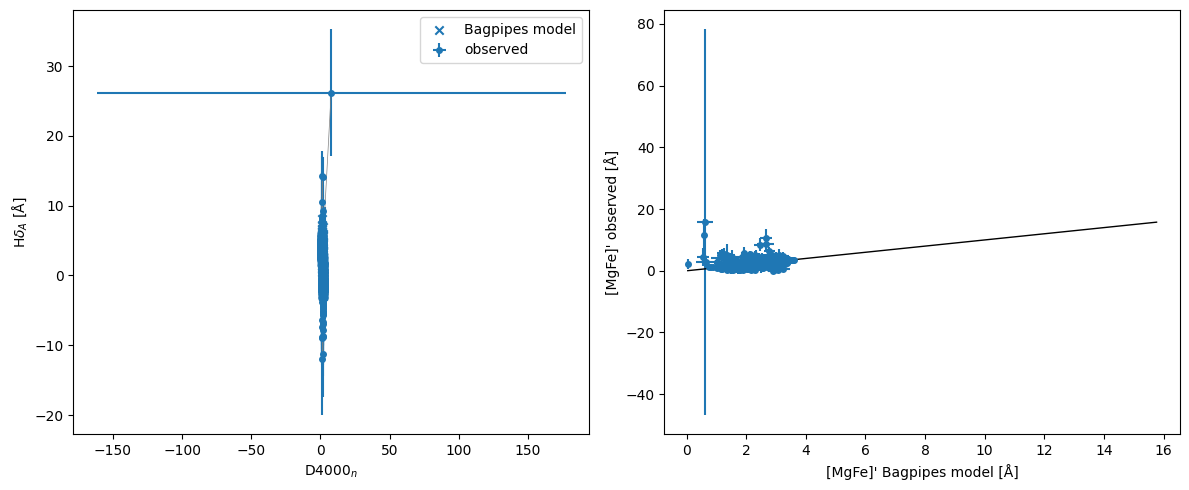

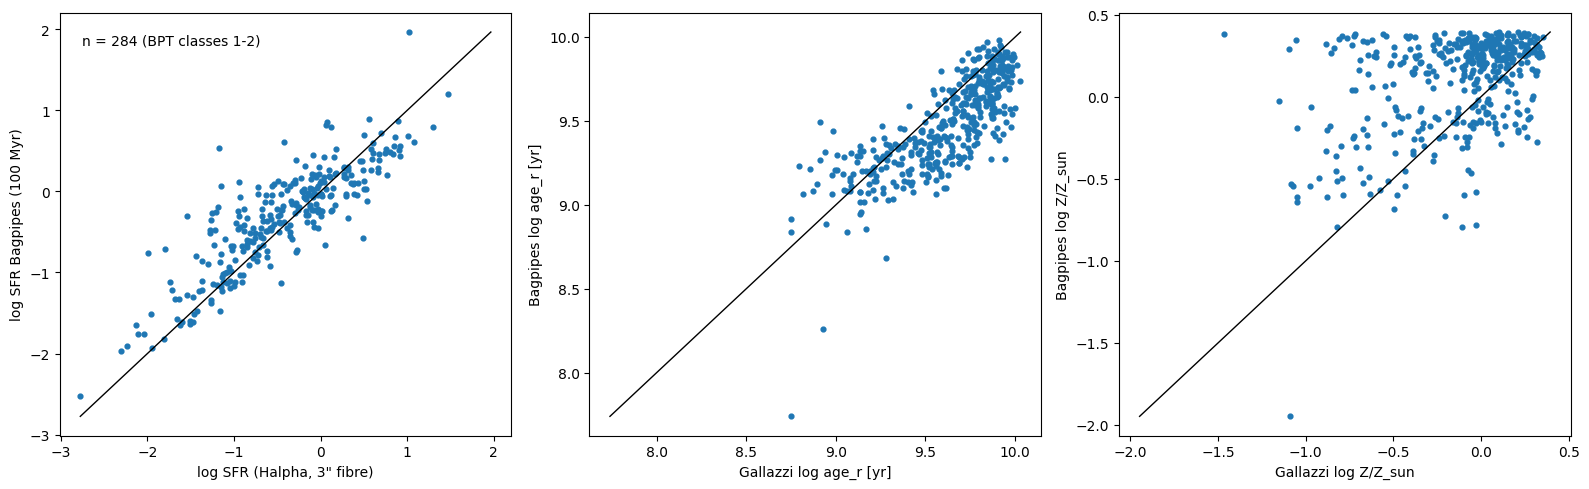

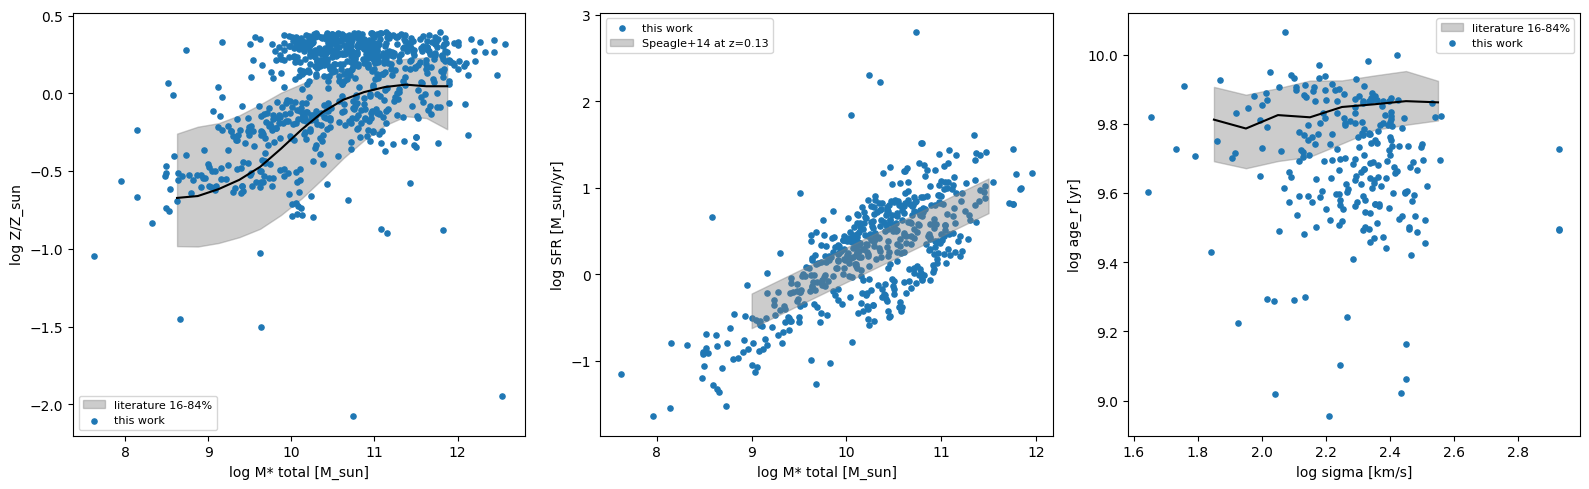

In [18]:
# Figure 1: indices, observed against posterior-predictive model
figure, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].errorbar(reference["D4000_n_obs"], reference["Hdelta_A_obs"], xerr=reference["D4000_n_obs_err"],
                 yerr=reference["Hdelta_A_obs_err"], fmt="o", ms=4, label="observed")
axes[0].scatter(reference["D4000_n_model_median"], reference["Hdelta_A_model_median"], marker="x",
                label="Bagpipes model")
for galaxy in reference.itertuples():
    axes[0].plot([galaxy.D4000_n_obs, galaxy.D4000_n_model_median],
                 [galaxy.Hdelta_A_obs, galaxy.Hdelta_A_model_median], color="grey", lw=0.5)
axes[0].set(xlabel="D4000$_n$", ylabel=r"H$\delta_A$ [Å]")
axes[0].legend()
axes[1].errorbar(reference["MgFe_prime_model_median"], reference["MgFe_prime_obs"],
                 yerr=reference["MgFe_prime_obs_err"], xerr=reference["MgFe_prime_model_std"], fmt="o", ms=4)
limits = [np.nanmin(reference["MgFe_prime_obs"]), np.nanmax(reference["MgFe_prime_obs"])]
axes[1].plot(limits, limits, color="black", lw=1)
axes[1].set(xlabel="[MgFe]' Bagpipes model [Å]", ylabel="[MgFe]' observed [Å]")
figure.tight_layout()
figure.savefig(INDEX_FIGURE_FILE, dpi=200)
plt.show()

# Figure 2: Halpha SFR and Gallazzi light-weighted age and metallicity
figure, axes = plt.subplots(1, 3, figsize=(16, 5))
comparisons = [
    (reference.loc[halpha_usable, "mpa_sfr_fib_p50"], reference.loc[halpha_usable, "log_sfr_median"],
     "log SFR (Halpha, 3\" fibre)", "log SFR Bagpipes (100 Myr)"),
    (reference["gallazzi_log_age_p50"], reference["log_age_light_median"],
     "Gallazzi log age_r [yr]", "Bagpipes log age_r [yr]"),
    (reference["gallazzi_log_z_p50"], reference["log_metallicity_median"],
     "Gallazzi log Z/Z_sun", "Bagpipes log Z/Z_sun"),
]
for axis, (literature_values, bagpipes_values, x_label, y_label) in zip(axes, comparisons):
    axis.scatter(literature_values, bagpipes_values, s=12)
    finite = np.isfinite(literature_values) & np.isfinite(bagpipes_values)
    if finite.any():
        limits = [min(literature_values[finite].min(), bagpipes_values[finite].min()),
                  max(literature_values[finite].max(), bagpipes_values[finite].max())]
        axis.plot(limits, limits, color="black", lw=1)
    else:
        axis.text(0.5, 0.5, "not available", transform=axis.transAxes, ha="center")
    axis.set(xlabel=x_label, ylabel=y_label)
# Few galaxies have an emission-line SFR: the count is on the panel, as a reminder that it is indicative only
axes[0].text(0.05, 0.95, f"n = {halpha_usable.sum()} (BPT classes 1-2)", transform=axes[0].transAxes, va="top")
figure.tight_layout()
figure.savefig(TRACER_FIGURE_FILE, dpi=200)
plt.show()

# Figure 3: scaling relations with their 16-84th bands
figure, axes = plt.subplots(1, 3, figsize=(16, 5))
panels = [(mass_metallicity_band, reference["log_mstar_total"], reference["log_metallicity_median"],
           "log M* total [M_sun]", "log Z/Z_sun"),
          (None, reference.loc[star_forming, "log_mstar_total"], reference.loc[star_forming, "log_sfr_total"],
           "log M* total [M_sun]", "log SFR [M_sun/yr]"),
          (age_sigma_band, log_sigma[passive.to_numpy()], log_age[passive.to_numpy()],
           "log sigma [km/s]", "log age_r [yr]")]
for axis, (band, x_values, y_values, x_label, y_label) in zip(axes, panels):
    if band is not None and len(band):
        centres = (band["x_low"] + band["x_high"]) / 2
        axis.fill_between(centres, band["y_p16"], band["y_p84"], color="grey", alpha=0.4,
                          label="literature 16-84%")
        axis.plot(centres, band["y_median"], color="black")
    axis.scatter(x_values, y_values, s=14, label="this work")
    axis.set(xlabel=x_label, ylabel=y_label)
mass_grid = np.linspace(9, 11.5, 50)
median_redshift = reference.loc[star_forming, "z"].median()
sequence_on_grid = sv.speagle_main_sequence(mass_grid, median_redshift)
axes[1].fill_between(mass_grid, sequence_on_grid - sv.SPEAGLE_SCATTER, sequence_on_grid + sv.SPEAGLE_SCATTER,
                     color="grey", alpha=0.4, label=f"Speagle+14 at z={median_redshift:.2f}")
for axis in axes:
    axis.legend(fontsize=8)
figure.tight_layout()
figure.savefig(RELATION_FIGURE_FILE, dpi=200)
plt.show()

In [19]:
boss = reference["fiber_diameter"].eq(2.0)
assert reference.loc[boss, "mpa_sfr_fib_p50"].isna().all(), "BOSS spectra have no MPA-JHU row"
mpa_index_offset = (reference["D4000_n_obs"] - reference["mpa_d4000_n"]).median()
print(f"Index code check: median D4000_n difference to MPA-JHU = {mpa_index_offset:.3f}")
for label, ours, theirs in (("Hdelta_A", "Hdelta_A_obs", "mpa_lick_hd_a"), ("Mgb", "Mgb_obs", "mpa_lick_mgb"),
                            ("Fe5270", "Fe5270_obs", "mpa_lick_fe5270"), ("Fe5335", "Fe5335_obs", "mpa_lick_fe5335")):
    print(f"Index code check: median {label} difference to MPA-JHU = {(reference[ours] - reference[theirs]).median():.3f}")

Index code check: median D4000_n difference to MPA-JHU = -0.001
Index code check: median Hdelta_A difference to MPA-JHU = 0.004
Index code check: median Mgb difference to MPA-JHU = 0.003
Index code check: median Fe5270 difference to MPA-JHU = 0.008
Index code check: median Fe5335 difference to MPA-JHU = 0.017


In [20]:
# The calibration verdict of the fitter (section 5) is stored on every row; empty while the mocks are incomplete
reference["fitter_calibrated"] = fitter_calibrated

reference.to_csv(OUTPUT_FILE, index=False)
assert reference.loc[fitted, "mw_age_median"].notna().all(), "A fitted galaxy has no labels in the output"
print(f"{OUTPUT_FILE}: {len(reference)} galaxies, {fitted.sum()} fitted, "
      f"{reference['converged'].eq(True).sum()} converged, {reference['covered'].sum()} covered; "
      f"fitter_calibrated = {fitter_calibrated}")
display(reference["split"].value_counts())

spectroscopic_reference.csv: 1362 galaxies, 755 fitted, 755 converged, 1325 covered; fitter_calibrated = False


split
excluded      623
validation    382
test          357
Name: count, dtype: int64

## Next pass
Raise `GALAXIES_PER_CELL` and re-run: the selection in `selection.csv` only grows (new picks are appended, every stored or fitted galaxy stays in the table), the new jobs are exported next to the old ones, and `run_spectral_fits.py` fits only the jobs without an `.h5` file. The stored calibration mocks (`MOCK_FILE`) are reused, so the calibration test stays valid, and the hash split never moves an existing galaxy. Mocks and fits of an earlier model are moved to `superseded/` by section 4, and new mocks are then drawn; to redraw mocks of the same model, move `MOCK_FILE` and the `calib_*` fits there by hand. Add DR4 Stripe 82 galaxies by pointing `SPLUS_FILE` at a DR4 catalogue with the same columns.